# DAMICORE v4: um universo por equipamento

No V3, com todos os pacientes juntos, a discretização separou os pacientes pelo **aparelho** quase tanto quanto pelo estado:
quase todos os controles são arquivos `fir` e todos os AD são `export`. No V4, cada equipamento vira um **universo separado**,
processado de forma independente do começo ao fim:

| Pasta | Arquivos | Taxa | Estados |
|---|---|---|---|
| `fir` | `*fir.mat` (inteiros) | 128 Hz | só CONTROL |
| `export128` | `export`, `float` | 128 Hz | CONTROL (normal1, normal2), MCI, AD |
| `export256` | `export`, `float` | 256 Hz | MCI, AD |

Em cada pasta:

| Passo | O que faz | No EDA |
|---|---|---|
| 1. Objetos | Sinais originais, sem reamostrar e sem filtrar; uma pasta por canal | população |
| 2. Discretização | DAMICORE em cada canal (NCD → árvore NJ) e corte em `K` grupos (caixa `K_DISCRETIZACAO`, padrão 2) | codificação |
| 3. Grupos de canais | DAMICORE na tabela de discretização, com os canais como objetos | estrutura (*linkage learning*) |
| 4. Tabelas de probabilidade | Uma tabela por grupo de canais | parâmetros do modelo |

**Um modelo por pasta, com todos os pacientes.** O estado (CONTROL, MCI, AD) não é usado pelo modelo: ele aparece só como rótulo nas figuras.
A pasta `fir` só tem controles, e as pastas `export` quase só AD e MCI, então não há classificação dentro de uma pasta.
Comparar estados fica para a etapa de juntar os universos.

O passo 5 gera o relatório da execução e o passo 6, o **relatório de decisões**: a árvore de possibilidades
com o caminho escolhido, montada a partir de `decisoes.yaml`.

A pasta é independente: os brutos ficam em `c:\DAMICORE\dataset` e são copiados para `dados/`, já separados por equipamento;
tudo o que é gerado vai para `saida/`.

## 0. Configuração

| Parâmetro | Valor | Motivo |
|---|---|---|
| `PASTAS` | `fir`, `export128`, `export256` | um universo por equipamento e taxa de amostragem |
| `N_AMOSTRAS` | 3840 | amostras por objeto: 30 s a 128 Hz e 15 s a 256 Hz. São 3840 valores `float32` (15 KB); o zlib só enxerga repetições até 32 KB para trás, então um par de objetos precisa caber nisso (a 0.5.0 recusa pares maiores que a janela do compressor) |
| `K_MAX_PAINEL` | 10 | maior K oferecido na caixa e no painel |
| `ALFA` | 1 | suavização de Laplace na coluna `prob_suavizada` das tabelas de probabilidade |

O K da discretização fica na caixa da seção 0.1, e o compressor de cada pasta na seção 0.2.

O notebook usa o DAMICORE **0.5.0**, no kernel `DAMICORE 0.5.0 (V4)` (ambiente `.venv05`).

In [1]:
from pathlib import Path
import base64, hashlib, html, io, json, os, re, shutil, sys, urllib.request, zipfile
from datetime import datetime
import numpy as np
import pandas as pd
import scipy.io as sio
import yaml
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

RAIZ = next((p for p in [Path.cwd(), Path.cwd() / 'DAMICORE_v4'] if (p / 'damicore_v4.ipynb').is_file()), Path.cwd())
FONTE = RAIZ.parent / 'dataset' / 'dataset'          # brutos, como baixados do figshare (compartilhados entre as versões)
DADOS = RAIZ / 'dados'
SAIDA = RAIZ / 'saida'
ARQ_DECISOES = RAIZ / 'decisoes.yaml'

PASTAS = {'fir': 'fir · 128 Hz', 'export128': 'export · 128 Hz', 'export256': 'export · 256 Hz'}
ESTADOS = ['CONTROL', 'MCI', 'AD']
CANAIS = ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T3', 'C3', 'Cz',
          'C4', 'T4', 'T5', 'P3', 'Pz', 'P4', 'T6', 'O1', 'O2']
N_AMOSTRAS = 3840
K_MAX_PAINEL = 10
ALFA = 1

CORES = {'CONTROL': '#2b2b28', 'MCI': '#7d7c74', 'AD': '#c9c8c0'}   # estados em cinza: não se confundem com as cores dos grupos
CORES_GRUPO = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#8c564b', '#17becf', '#bcbd22']

import damicore
assert damicore.__version__ == '0.5.0', f'este notebook usa o damicore 0.5.0 (kernel DAMICORE 0.5.0 (V4)); o kernel atual tem {damicore.__version__}'
SAIDA.mkdir(exist_ok=True)
pd.set_option('display.width', 200)
sys.setrecursionlimit(10000)

FIGURAS = {}                                          # figuras guardadas para o relatório do passo 5
def mostrar(fig, nome=None):
    if nome:
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=100, bbox_inches='tight', facecolor='white')
        FIGURAS[nome] = base64.b64encode(buf.getvalue()).decode()
    plt.show()

def cor_grupo(g):
    return CORES_GRUPO[int(g) % len(CORES_GRUPO)]

print('Brutos:', FONTE)
print('Dados: ', DADOS)
print('Saída: ', SAIDA)

Brutos: C:\DAMICORE\dataset\dataset
Dados:  C:\DAMICORE\DAMICORE_v4\dados
Saída:  C:\DAMICORE\DAMICORE_v4\saida


### 0.1 Discretização: `K_DISCRETIZACAO`

**Esta é a caixa da discretização.** Cada árvore de canal é cortada em K grupos, e o grupo de um paciente é o seu símbolo naquele canal:
com K = 2 os símbolos são 0 e 1; com K = 3, 0, 1 e 2; e assim por diante (de 2 a `K_MAX_PAINEL`).

Um valor por pasta, padrão 2. Canais específicos podem ser ajustados no painel da seção 2.4; o ajuste vale só para aquele canal.

Com K maior, um grupo de *g* canais admite K<sup>g</sup> padrões. Com poucas dezenas de pacientes nas pastas `export`,
as tabelas de probabilidade ficam esparsas rápido; o passo 4 mostra isso.

In [2]:
K_DISCRETIZACAO = {'fir': 2, 'export128': 2, 'export256': 2}

In [3]:
assert set(K_DISCRETIZACAO) == set(PASTAS), f'K_DISCRETIZACAO precisa ter as pastas {list(PASTAS)}'
assert all(2 <= int(k) <= K_MAX_PAINEL for k in K_DISCRETIZACAO.values()), f'K deve ficar entre 2 e {K_MAX_PAINEL}'
print('K por pasta:', K_DISCRETIZACAO)

K por pasta: {'fir': 2, 'export128': 2, 'export256': 2}


### 0.2 Compressor do NCD: `COMPRESSOR`

O NCD mede a semelhança entre dois objetos pelo quanto um ajuda a comprimir o outro, e o resultado depende do compressor.
A 0.5.0 oferece quatro (`zlib`, `ppmd`, `lzma`, `bzip2`). Sem orientação prévia, os quatro foram testados nos objetos do V4
(`testes/teste_compressores.py`; 5 canais × 3 pastas), com critérios definidos antes de ver os resultados e aplicados nesta ordem:

1. **validade:** o compressor reconhece um objeto repetido (NCD(x, x) perto de 0) e nenhum par passa da janela dele;
2. **identificação:** com duas janelas vizinhas de cada paciente, o vizinho mais próximo de uma janela é a outra do mesmo paciente? (e a AUC intra × entre pacientes);
3. **estabilidade:** o corte K=2 feito com as janelas A coincide com o das janelas B (ARI);
4. **custo.**

Resultado: nenhum compressor vence em todas as pastas. O `bzip2` falha na validade em todas; o `ppmd` falha na pasta `fir` (inteiros) e é o melhor
nas pastas `export`; na `fir`, entre os válidos, o `zlib` identifica e estabiliza um pouco melhor que o `lzma` e custa um terço.
A tabela abaixo (lida do resultado do teste, sem refazê-lo) e o `decisoes.yaml` registram os números.

`COMPRESSOR_ESTRUTURA` é o compressor do passo 3 (canais como objetos, um byte por paciente). Ele não foi testado e fica no `zlib`, como no V3.

In [4]:
COMPRESSOR = {'fir': 'zlib', 'export128': 'ppmd', 'export256': 'ppmd'}
COMPRESSOR_ESTRUTURA = 'zlib'

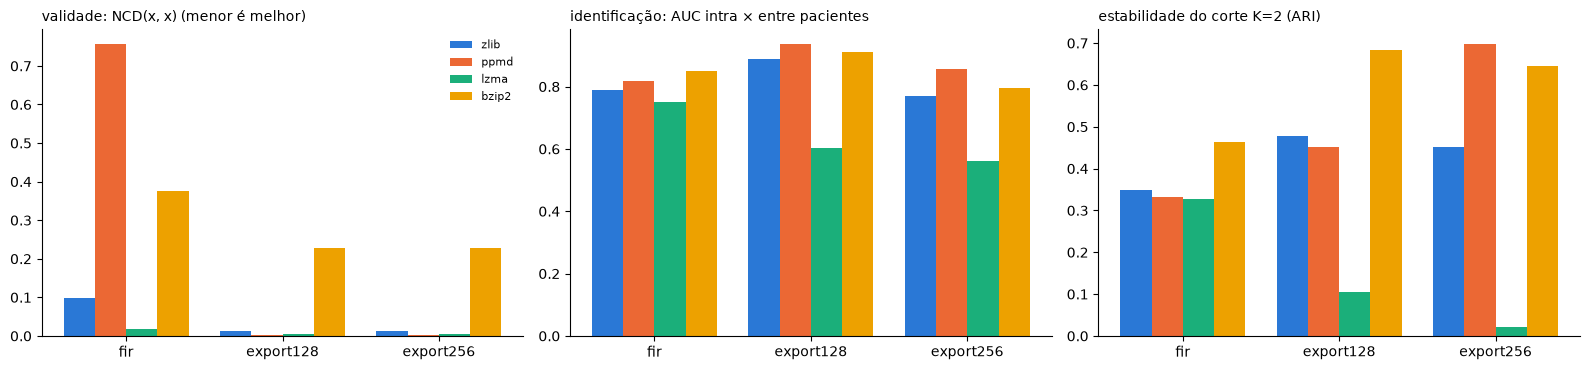

ncd_self_largest  ident_top1  auc_intra_inter  estabilidade_k2_ari  ncd_inter_mediana  tempo_s escolhido
pasta     compressor                                                                                                          
fir       bzip2                  0.376       0.108            0.849                0.464              0.930    39.40          
          lzma                   0.018       0.081            0.751                0.328              0.907    93.90          
          ppmd                   0.757       0.089            0.817                0.333              0.938    44.00          
          zlib                   0.098       0.109            0.788                0.348              0.942    31.66         ✓
export128 bzip2                  0.228       0.169            0.911                0.683              0.975    11.70          
          lzma                   0.004       0.050            0.603                0.105              0.997    14.44          
          ppmd                   0.003       0.238            0.937                0.452              0.997    11.42         ✓
          zlib                   0.012       0.092            0.888                0.478              1.001     8.00          
export256 bzip2                  0.228       0.127            0.795                0.646              0.969    14.68          
          lzma                   0.004       0.073            0.562                0.022              0.994    27.14          
          ppmd                   0.003       0.176            0.855                0.698              0.985    20.00         ✓
          zlib                   0.012       0.116            0.769                0.452              1.000    10.72

Compressor por pasta: {'fir': 'zlib', 'export128': 'ppmd', 'export256': 'ppmd'} | passo 3: zlib


In [5]:
assert set(COMPRESSOR) == set(PASTAS) and set(COMPRESSOR.values()) | {COMPRESSOR_ESTRUTURA} <= {'zlib', 'ppmd', 'lzma', 'bzip2'}
ARQ_TESTE = SAIDA / 'teste_compressores' / 'resultados.csv'
if ARQ_TESTE.is_file():
    TESTE = pd.read_csv(ARQ_TESTE)
    RESUMO_TESTE = TESTE.groupby(['pasta', 'compressor'])[['ncd_self_largest', 'ident_top1', 'auc_intra_inter', 'estabilidade_k2_ari',
                                                          'ncd_inter_mediana', 'tempo_s']].mean().round(3)
    RESUMO_TESTE['escolhido'] = ['✓' if COMPRESSOR.get(p) == c else '' for p, c in RESUMO_TESTE.index]
    RESUMO_TESTE = RESUMO_TESTE.reindex(list(PASTAS), level=0)
    fig, eixos = plt.subplots(1, 3, figsize=(16, 3.8))
    ordem_c = ['zlib', 'ppmd', 'lzma', 'bzip2']
    for ax, (col, titulo) in zip(eixos, [('ncd_self_largest', 'validade: NCD(x, x) (menor é melhor)'),
                                         ('auc_intra_inter', 'identificação: AUC intra × entre pacientes'),
                                         ('estabilidade_k2_ari', 'estabilidade do corte K=2 (ARI)')]):
        for j, c in enumerate(ordem_c):
            v = [RESUMO_TESTE.loc[(p, c), col] for p in PASTAS]
            ax.bar(np.arange(len(PASTAS)) + (j - 1.5) * 0.2, v, 0.2, color=CORES_GRUPO[j], label=c)
        ax.set_xticks(range(len(PASTAS)), list(PASTAS))
        ax.set_title(titulo, loc='left', fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)
    eixos[0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    mostrar(fig, 'compressores')
    display(RESUMO_TESTE)
else:
    TESTE = RESUMO_TESTE = None
    print('Resultado do teste de compressores não encontrado; rode testes/teste_compressores.py com o .venv05.')
print('Compressor por pasta:', COMPRESSOR, '| passo 3:', COMPRESSOR_ESTRUTURA)

## 1. Passo 1 — Objetos

### 1.1 Cópia dos dados, separados por equipamento

Os brutos em `c:\DAMICORE\dataset\dataset` (pastas `CONTROL`, `AD`, `MCI` e `readme.txt`) são copiados para `dados/`, organizados pelo aparelho:

```
dados/
├── fir/         10057fir.mat ...           (CONTROL)
├── export128/   normal1/ AD1/ MCI5/ ...    (uma pasta por paciente, segmentos 1.mat, 2.mat, ...)
├── export256/   AD2/ MCI1/ ...
├── readme.txt
└── organizacao.csv                          (paciente, estado, pasta, taxa, origem e destino de cada arquivo)
```

Todos os arquivos são copiados, inclusive os segmentos que depois não são usados: nada se perde na cópia.
A taxa de cada paciente `export` vem do `readme.txt`. A cópia só acontece uma vez; se `dados/organizacao.csv` já existe, ela é reaproveitada.
Se os brutos não existirem, a célula baixa o dataset original do figshare (293 MB) para `c:\DAMICORE\dataset`.

In [6]:
def ler_readme(caminho):
    linhas = []
    for l in caminho.read_text(encoding='latin-1').splitlines():
        p = l.split('\t')
        if len(p) == 8 and p[7].strip() and p[0].strip().isdigit():
            linhas.append(dict(paciente=p[7].strip(), escore=int(p[5]), fs=int(p[6])))
    return pd.DataFrame(linhas).set_index('paciente')

def obter_fonte():
    if (FONTE / 'readme.txt').is_file():
        return FONTE
    print('Baixando o dataset do figshare (doi:10.6084/m9.figshare.5450293)...')
    with urllib.request.urlopen('https://ndownloader.figshare.com/files/9423433') as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(FONTE.parent)
    return next(FONTE.parent.rglob('readme.txt')).parent

def organizar(fonte):
    arq = DADOS / 'organizacao.csv'
    if arq.is_file():
        return pd.read_csv(arq).set_index('paciente')
    readme = ler_readme(fonte / 'readme.txt')
    linhas = []
    for estado in ESTADOS:
        for item in sorted((fonte / estado).iterdir()):
            if item.is_file() and item.name.endswith('fir.mat'):
                pasta, fs = 'fir', 128
                destino = DADOS / pasta / item.name
                destino.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(item, destino)
            elif item.is_dir():
                fs = int(readme.loc[item.name, 'fs'])
                pasta = f'export{fs}'
                destino = DADOS / pasta / item.name
                shutil.copytree(item, destino, dirs_exist_ok=True)
            else:
                continue
            linhas.append(dict(paciente=item.name.removesuffix('.mat'), estado=estado, pasta=pasta, fs=fs,
                               origem=os.path.relpath(item, RAIZ.parent), destino=os.path.relpath(destino, RAIZ)))
    shutil.copy2(fonte / 'readme.txt', DADOS / 'readme.txt')
    org = pd.DataFrame(linhas).set_index('paciente')
    assert set(org.pasta) <= set(PASTAS), f'pasta inesperada: {set(org.pasta) - set(PASTAS)}'
    org.to_csv(arq)
    return org

ORGANIZACAO = organizar(obter_fonte())
tamanho = sum(f.stat().st_size for f in DADOS.rglob('*.mat')) / 2**20
print(f'{len(ORGANIZACAO)} pacientes copiados para {DADOS} ({tamanho:.0f} MB)')
pd.crosstab(ORGANIZACAO.pasta, ORGANIZACAO.estado, margins=True, margins_name='total').reindex(
    index=list(PASTAS) + ['total'], columns=ESTADOS + ['total'], fill_value=0)

168 pacientes copiados para C:\DAMICORE\DAMICORE_v4\dados (292 MB)


estado,CONTROL,MCI,AD,total
pasta,,,,
fir,100,0,0,100
export128,2,3,25,30
export256,0,4,34,38
total,102,7,59,168


### 1.2 Leitura do sinal e retirada de pacientes

- **`fir`:** um arquivo por paciente, variável `segmenty` (canais × amostras, valores inteiros); as 19 primeiras linhas são o EEG.
- **`export`:** vários segmentos `.mat` por paciente, variável `export` (amostras × canais). Segmentos com 17, 18 ou 20 colunas são ignorados,
  porque não dá para saber qual coluna é qual canal.

O sinal de um paciente é a concatenação dos seus segmentos, com os valores originais, e dele é recortada uma janela central de `N_AMOSTRAS`.
Um paciente é retirado se não tiver nenhum segmento de 19 canais, se o sinal for menor que a janela, ou se algum canal for plano
(todos os valores iguais): dois objetos idênticos dariam NCD = 0.

In [7]:
def segmentos(pasta):
    return sorted(pasta.glob('*.mat'), key=lambda f: int(f.stem))

def ler_sinal(pid, linha):
    caminho = RAIZ / linha.destino
    if linha.pasta == 'fir':
        return sio.loadmat(caminho)['segmenty'][:19].T.astype(np.float64)
    partes = [x for x in (sio.loadmat(f)['export'] for f in segmentos(caminho)) if x.shape[1] == 19]
    return np.concatenate(partes).astype(np.float64) if partes else None

def janela_central(x, n=N_AMOSTRAS):
    ini = (len(x) - n) // 2
    return x[ini:ini + n]

JANELAS, RETIRADOS = {}, []
for pid, linha in ORGANIZACAO.iterrows():
    x = ler_sinal(pid, linha)
    if x is None:
        RETIRADOS.append(dict(paciente=pid, estado=linha.estado, pasta=linha.pasta, motivo='nenhum segmento de 19 canais'))
        continue
    if len(x) < N_AMOSTRAS:
        RETIRADOS.append(dict(paciente=pid, estado=linha.estado, pasta=linha.pasta, motivo=f'sinal curto ({len(x)} amostras)'))
        continue
    j = janela_central(x).astype(np.float32)
    planos = [c for i, c in enumerate(CANAIS) if j[:, i].std() == 0]
    if planos:
        RETIRADOS.append(dict(paciente=pid, estado=linha.estado, pasta=linha.pasta, motivo='canal plano: ' + ', '.join(planos)))
        continue
    JANELAS[pid] = j

RETIRADOS = pd.DataFrame(RETIRADOS, columns=['paciente', 'estado', 'pasta', 'motivo'])
pacientes = ORGANIZACAO.loc[list(JANELAS), ['estado', 'pasta', 'fs']]
pacientes.to_csv(SAIDA / 'pacientes.csv')
RETIRADOS.to_csv(SAIDA / 'pacientes_retirados.csv', index=False)
PACIENTES = {p: pacientes.index[pacientes.pasta == p].tolist() for p in PASTAS}
ESTADOS_PASTA = {p: [e for e in ESTADOS if (pacientes.loc[PACIENTES[p], 'estado'] == e).any()] for p in PASTAS}
BYTES_OBJETO = N_AMOSTRAS * np.dtype(np.float32).itemsize
print('Retirados:')
display(RETIRADOS)
print('No estudo:')
pd.crosstab(pacientes.pasta, pacientes.estado, margins=True, margins_name='total').reindex(
    index=list(PASTAS) + ['total'], columns=ESTADOS + ['total'], fill_value=0)

Retirados:


,paciente,estado,pasta,motivo
0,26887fir,CONTROL,fir,canal plano: Cz
1,7147fir,CONTROL,fir,canal plano: Cz
2,AD33,AD,export256,nenhum segmento de 19 canais
3,AD44,AD,export128,nenhum segmento de 19 canais


No estudo:


estado,CONTROL,MCI,AD,total
pasta,,,,
fir,98,0,0,98
export128,2,3,24,29
export256,0,4,33,37
total,100,7,57,164


### 1.3 Objetos: uma pasta por canal, dentro de cada pasta de equipamento

```
saida/<pasta>/objetos/
├── Fp1/   <paciente>.bin ...    (3840 valores float32, o sinal original)
├── Fp2/
└── ...  (19 canais)
```

In [8]:
for pasta in PASTAS:
    dir_obj = SAIDA / pasta / 'objetos'
    if dir_obj.exists():
        shutil.rmtree(dir_obj)
    for pid in PACIENTES[pasta]:
        for i, canal in enumerate(CANAIS):
            (dir_obj / canal).mkdir(parents=True, exist_ok=True)
            (dir_obj / canal / f'{pid}.bin').write_bytes(np.ascontiguousarray(JANELAS[pid][:, i]).tobytes())
    print(f'{pasta:>9}: {len(PACIENTES[pasta])} pacientes x 19 canais, {BYTES_OBJETO} bytes por objeto -> {dir_obj}')

      fir: 98 pacientes x 19 canais, 15360 bytes por objeto -> C:\DAMICORE\DAMICORE_v4\saida\fir\objetos


export128: 29 pacientes x 19 canais, 15360 bytes por objeto -> C:\DAMICORE\DAMICORE_v4\saida\export128\objetos


export256: 37 pacientes x 19 canais, 15360 bytes por objeto -> C:\DAMICORE\DAMICORE_v4\saida\export256\objetos


### 1.4 O mesmo canal em um paciente de cada pasta

Os primeiros 4 s do canal P3, com os valores originais. Cada painel tem o seu eixo vertical: os `fir` são inteiros e os `export`, valores pequenos.
Dentro de uma pasta, todos os pacientes têm a mesma escala e a mesma taxa.

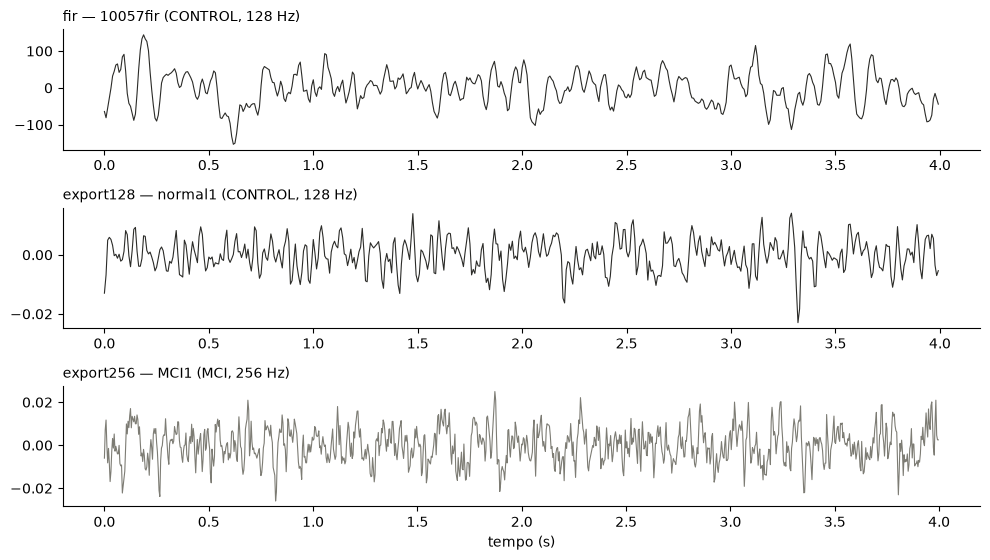

In [9]:
CANAL_EXEMPLO = 'P3'
i = CANAIS.index(CANAL_EXEMPLO)
fig, eixos = plt.subplots(len(PASTAS), 1, figsize=(10, 1.9 * len(PASTAS)))
for ax, pasta in zip(eixos, PASTAS):
    pid = PACIENTES[pasta][0]
    p = pacientes.loc[pid]
    t = np.arange(4 * p.fs) / p.fs
    ax.plot(t, JANELAS[pid][:len(t), i], color=CORES[p.estado] if p.estado != 'AD' else '#8c8b83', lw=0.8)
    ax.set_title(f'{pasta} — {pid} ({p.estado}, {p.fs} Hz)', loc='left', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
eixos[-1].set_xlabel('tempo (s)')
fig.tight_layout()
mostrar(fig, 'sinais')

## 2. Passo 2 — Discretização

### 2.1 DAMICORE em cada canal de cada pasta

Cada pasta de canal é a entrada de uma execução do DAMICORE (`source_kind='files'`): NCD entre todos os pares de pacientes da pasta,
árvore por Neighbor Joining e número automático de grupos pela modularidade (o **k automático**, só informativo: o K usado é o da caixa).

São 19 × 3 = 57 execuções. Uma execução já concluída com os mesmos objetos é reaproveitada, então só a primeira vez demora.

In [10]:
from damicore import run, ExecutionConfig, OutputDirectoryConflictError, DamicoreError

def damicore_canal(pasta, canal):
    destino = SAIDA / pasta / f'damicore_canais_{COMPRESSOR[pasta]}' / canal
    args = dict(source_kind='files', compressor=COMPRESSOR[pasta], num_clusters=None, output_dir=destino, progress=False,
                execution=ExecutionConfig(workers='auto'))
    for tentativa in range(3):
        try:
            r = run(SAIDA / pasta / 'objetos' / canal, **args)
            break
        except OutputDirectoryConflictError:      # objetos mudaram desde a última execução: refaz
            shutil.rmtree(destino)
        except DamicoreError as e:                # Windows: arquivo temporário bloqueado; retoma do checkpoint
            if 'PermissionError' not in str(e) or tentativa == 2:
                raise
    r.close()
    return destino

linhas = []
for pasta in PASTAS:
    for canal in CANAIS:
        rel = json.loads((damicore_canal(pasta, canal) / 'report.json').read_text(encoding='utf-8'))
        linhas.append(dict(pasta=pasta, canal=canal, objetos=rel['object_count'], pares=rel['pair_count'],
                           k_automatico=rel['cluster_count'], modularidade=round(rel['modularity'], 3),
                           tempo_s=round(rel['timings_seconds']['total'], 1)))
    t = sum(l['tempo_s'] for l in linhas if l['pasta'] == pasta)
    print(f'{pasta:>9}: 19 canais, {linhas[-1]["objetos"]} pacientes, {t:.0f} s')
EXECUCOES = pd.DataFrame(linhas).set_index(['pasta', 'canal'])
EXECUCOES.groupby('pasta', sort=False).agg(pacientes=('objetos', 'first'), pares=('pares', 'first'),
                                          k_auto_min=('k_automatico', 'min'), k_auto_max=('k_automatico', 'max'),
                                          tempo_s=('tempo_s', 'sum'))

      fir: 19 canais, 98 pacientes, 274 s


export128: 19 canais, 29 pacientes, 70 s


export256: 19 canais, 37 pacientes, 96 s


,pacientes,pares,k_auto_min,k_auto_max,tempo_s
pasta,,,,,
fir,98,4753,11,15,274.4
export128,29,406,6,8,69.5
export256,37,666,7,9,96.5


### 2.2 Os cortes de cada árvore

O FastGreedy divide uma árvore em K grupos **cortando K−1 ramos**, e os cortes são aninhados: o corte de K=3 mantém o ramo de K=2 e acrescenta outro.
Esta célula calcula, para cada árvore, os cortes de K=2 até `K_MAX_PAINEL`, com o mesmo FastGreedy do DAMICORE e sem refazer o NCD.

O mapa mostra a **modularidade** de cada corte (quanto os grupos são mais coesos do que o acaso). Diferente do V3, o mapa não usa o estado:
dentro de uma pasta o estado não é o alvo.

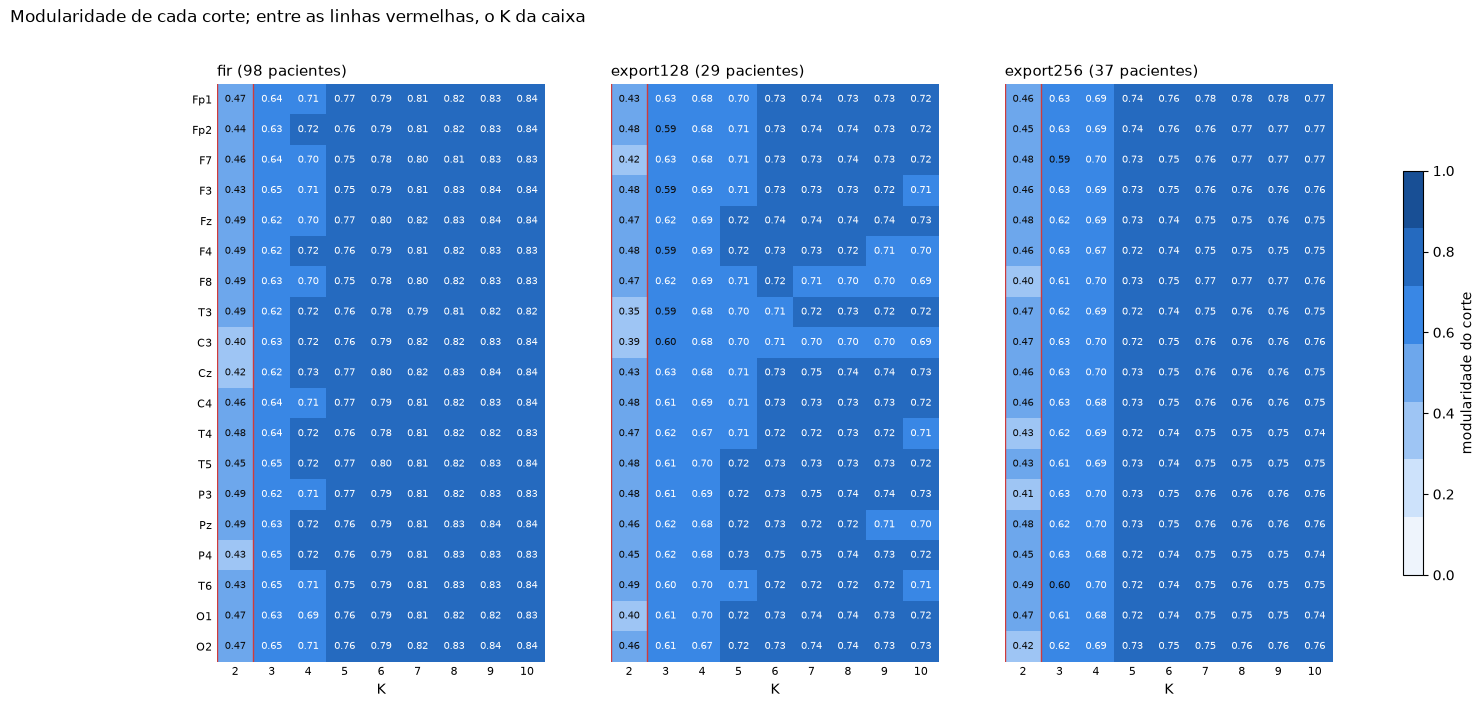

In [11]:
from damicore_clusterizer import cluster_tree, ClusterConfig
from damicore_clusterizer.tree_graph import load_tree_graph
from damicore_clusterizer.fastgreedy import fastgreedy_membership
from sklearn.metrics import adjusted_rand_score

def preparar_arvore(pasta, canal):
    # Layout do filograma e, para cada K, os grupos de cada nó e os ramos cortados
    caminho = SAIDA / pasta / f'damicore_canais_{COMPRESSOR[pasta]}' / canal / 'tree.json'
    arv = json.loads(caminho.read_text(encoding='utf-8'))
    src = load_tree_graph(caminho.resolve())
    paciente = {oid: rot.removesuffix('.bin') for oid, rot in src.labels.items()}
    filhos, comp, pai = {}, {}, {}
    for e in arv['edges']:
        filhos.setdefault(e['source'], []).append(e['target'])
        comp[e['target']] = e['length']
        pai[e['target']] = e['source']
    x, y, folhas = {}, {}, []

    def posicionar(no, x0):
        x[no] = x0
        if no not in filhos:
            y[no] = len(folhas)
            folhas.append(no)
            return
        for f in filhos[no]:
            posicionar(f, x0 + comp[f])
        y[no] = np.mean([y[f] for f in filhos[no]])

    posicionar(arv['root_id'], 0.0)
    prof = {}
    def profundidade(no, d):
        prof[no] = d
        for f in filhos.get(no, []):
            profundidade(f, d + 1)
    profundidade(arv['root_id'], 0)
    dmax = max(prof.values())
    x_topo = {no: (prof[no] if no in filhos else dmax) for no in prof}
    alt = {}
    def altura(no):
        alt[no] = 0 if no not in filhos else 1 + max(altura(f) for f in filhos[no])
        return alt[no]
    altura(arv['root_id'])
    x_clad = {no: alt[arv['root_id']] - alt[no] for no in alt}   # cladograma: nó pela altura, folhas alinhadas
    x_topol = dict(prof)                                         # topológica: todo ramo com comprimento 1
    kmax = int(min(K_MAX_PAINEL, len(src.object_ids) - 1))
    cortes, grupo_no, particao, modularidade = {}, {}, {}, {}
    for k in range(2, kmax + 1):
        memb, _, mod = fastgreedy_membership(src.graph, k)
        com = {src.vertex_names[v]: c for v, c in enumerate(memb)}
        for no in filhos:                          # a raiz do NJ não é vértice do grafo sem raiz: herda o grupo do primeiro filho
            if no not in com:
                com[no] = com[filhos[no][0]] if filhos[no][0] in com else com[filhos[no][1]]
        por_com = {}
        for oid in src.object_ids:
            por_com.setdefault(com[oid], []).append(oid)
        ordenados = sorted(tuple(sorted(g)) for g in por_com.values())   # mesma numeração do cluster_tree
        numero = {com[g[0]]: i for i, g in enumerate(ordenados)}
        grupo_no[k] = {no: numero.get(c, -1) for no, c in com.items()}
        particao[k] = pd.Series({paciente[oid]: grupo_no[k][oid] for oid in src.object_ids})
        modularidade[k] = mod
        for filho, p in pai.items():
            if com[filho] != com[p] and (p, filho) not in cortes:
                cortes[p, filho] = k
    return dict(pasta=pasta, canal=canal, x={'comprimento': x, 'topologia': x_topo, 'cladograma': x_clad, 'topologica': x_topol}, y=y, folhas=folhas, filhos=filhos,
                paciente=paciente, kmax=kmax, cortes=cortes, grupo_no=grupo_no, particao=particao, modularidade=modularidade)

ARVORES = {(p, c): preparar_arvore(p, c) for p in PASTAS for c in CANAIS}

fig, eixos = plt.subplots(1, len(PASTAS), figsize=(18, 7.5), sharey=True)
cmap_mod = ListedColormap(['#eef4fc', '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95'])
for ax, pasta in zip(eixos, PASTAS):
    mod = pd.DataFrame({k: {c: ARVORES[pasta, c]['modularidade'].get(k, np.nan) for c in CANAIS}
                        for k in range(2, K_MAX_PAINEL + 1)}).reindex(CANAIS)
    im = ax.imshow(np.ma.masked_invalid(mod.values), cmap=cmap_mod, vmin=0, vmax=1, aspect='auto')
    for i in range(mod.shape[0]):
        for j in range(mod.shape[1]):
            v = mod.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='#ffffff' if v > 0.6 else '#0b0b0b')
    kc = K_DISCRETIZACAO[pasta] - 2
    ax.axvline(kc - 0.5, color='#d03b3b', lw=1); ax.axvline(kc + 0.5, color='#d03b3b', lw=1)
    ax.set_xticks(range(mod.shape[1]), [str(k) for k in mod.columns], fontsize=8)
    ax.set_yticks(range(len(CANAIS)), CANAIS, fontsize=8)
    ax.set_xlabel('K'); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f'{pasta} ({len(PACIENTES[pasta])} pacientes)', loc='left', fontsize=11)
fig.colorbar(im, ax=eixos, shrink=0.7, label='modularidade do corte')
fig.suptitle('Modularidade de cada corte; entre as linhas vermelhas, o K da caixa', x=0.01, ha='left', fontsize=12)
mostrar(fig, 'mapa_k')

### 2.3 Desenho do corte

Cada árvore é desenhada a partir da raiz gravada pelo DAMICORE. Há quatro desenhos; eles mudam só o comprimento horizontal dos ramos,
não a topologia nem os grupos do corte:

- **como estava** (`topologia`): nós internos pela distância à raiz, em número de ramos, e folhas esticadas até a borda direita;
- **cladograma**: folhas alinhadas e cada nó interno pela sua altura (número de ramos até a folha mais distante abaixo dele);
- **topológica**: todo ramo com comprimento 1; cada folha fica na sua profundidade;
- **filograma** (`comprimento`): o comprimento horizontal é o NCD do ramo.

Para comparar, cada pasta é desenhada num estilo (`ESCALA_PASTA`): `fir` como estava, `export128` em cladograma e `export256` em topológica.
No painel, os quatro desenhos podem ser trocados.

- **Ramos coloridos:** cada cor é um grupo do corte; cinza, parte da árvore sem paciente.
- **Ramos cortados:** tracejado vermelho, com um círculo e o número do corte. Números cinza: os próximos cortes, se o K aumentar.
- **Duas faixas à direita das folhas:** o estado do paciente (rótulo, não usado pelo DAMICORE: preto = CONTROL, cinza = MCI, cinza-claro = AD) e o grupo do corte.

In [12]:
COR_CORTE = '#d03b3b'
ESCALA_PASTA = {'fir': 'topologia', 'export128': 'cladograma', 'export256': 'topologica'}
NOME_ESCALA = {'topologia': 'como estava', 'cladograma': 'cladograma', 'topologica': 'topológica', 'comprimento': 'filograma'}
EIXO_ESCALA = {'topologia': 'nível a partir da raiz; folhas esticadas até a borda (como estava)',
               'cladograma': 'cladograma: nós pela altura, folhas alinhadas',
               'topologica': 'topológica: todo ramo com comprimento 1',
               'comprimento': 'filograma: comprimento acumulado dos ramos (NCD)'}

def desenhar_corte(ax, A, k, compacto=False, escala='topologia'):
    x, y, grupo = A['x'][escala], A['y'], A['grupo_no'][k]
    cor = lambda no: cor_grupo(grupo[no]) if grupo[no] >= 0 else '#b9b8b0'
    lw = 0.7 if compacto else 1.3
    for p, fs in A['filhos'].items():
        ax.plot([x[p], x[p]], [min(y[f] for f in fs), max(y[f] for f in fs)], color=cor(p), lw=lw, solid_capstyle='butt')
        for f in fs:
            kc = A['cortes'].get((p, f))
            xm = (x[p] + x[f]) / 2
            if kc is not None and kc <= k:
                ax.plot([x[p], x[f]], [y[f], y[f]], color=COR_CORTE, lw=lw * 1.4, ls=(0, (2, 1.2)))
                ax.scatter(xm, y[f], s=70 if compacto else 260, color=COR_CORTE, edgecolor='white', linewidth=1.2, zorder=5)
                ax.text(xm, y[f], str(kc - 1), ha='center', va='center', color='white', fontsize=6 if compacto else 9,
                        fontweight='bold', zorder=6)
            else:
                ax.plot([x[p], x[f]], [y[f], y[f]], color=cor(f), lw=lw)
                if kc is not None and not compacto:
                    ax.text(xm, y[f] - 0.6, str(kc - 1), ha='center', va='bottom', color='#9a998f', fontsize=7)
    xmax = max(x.values())
    for f in A['folhas']:
        p = A['paciente'][f]
        ax.add_patch(Rectangle((xmax * 1.03, y[f] - 0.5), xmax * 0.04, 1, color=CORES[pacientes.loc[p, 'estado']], lw=0))
        ax.add_patch(Rectangle((xmax * 1.08, y[f] - 0.5), xmax * 0.04, 1, color=cor(f), lw=0))
    if not compacto:
        ax.text(xmax * 1.05, -1.5, 'estado', rotation=90, ha='center', va='bottom', fontsize=8, color='#5f5e57')
        ax.text(xmax * 1.10, -1.5, 'grupo', rotation=90, ha='center', va='bottom', fontsize=8, color='#5f5e57')
        ax.set_xlabel(EIXO_ESCALA[escala])
        if len(A['folhas']) <= 40:                 # pastas pequenas: o nome de cada paciente
            for f in A['folhas']:
                ax.text(xmax * 1.13, y[f], A['paciente'][f], va='center', fontsize=7, color='#5f5e57')
    ax.set_xlim(-xmax * 0.02, xmax * (1.14 if compacto or len(A['folhas']) > 40 else 1.3))
    ax.set_ylim(len(A['folhas']) - 0.5, -0.5 - (0 if compacto else 8))
    ax.set_yticks([])
    if compacto:
        ax.set_xticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)

def composicao(pasta, part):
    # Pacientes de cada estado (rótulo) em cada grupo do corte
    est = pacientes.loc[PACIENTES[pasta], 'estado']
    return pd.crosstab(part.reindex(est.index).rename('grupo'), est).reindex(columns=ESTADOS_PASTA[pasta], fill_value=0)

def legenda_corte(ax, k, estados, dentro=False):
    alcas = ([Line2D([], [], marker='s', ls='', markersize=9, color=CORES[e], label=e) for e in estados] +
             [Line2D([], [], marker='s', ls='', markersize=9, color=cor_grupo(g), label=f'grupo {g}') for g in range(k)] +
             [Line2D([], [], marker='o', ls='--', color=COR_CORTE, markersize=9, label='ramo cortado (nº do corte)')])
    if dentro:
        ax.legend(handles=alcas, loc='center', frameon=False, fontsize=9, ncol=2)
    else:
        ax.legend(handles=alcas, loc='upper left', bbox_to_anchor=(0, -0.06), frameon=False, fontsize=8, ncol=4)

### 2.4 Painel: corte interativo das árvores de canais

**Como usar:**
1. Escolha a pasta e o canal e mova o K: a árvore é redesenhada com o corte, e a linha abaixo mostra quantos pacientes de cada estado caíram em cada grupo.
2. O K de cada canal começa no valor da caixa `K_DISCRETIZACAO` da pasta. Mudar o K de um canal cria um **ajuste** só para ele
   (a linha "K por canal" mostra os ajustes em negrito).
3. Clique em **Gravar ajustes** para salvar em `saida/k_ajustes.json`, ou **Limpar ajustes da pasta** para voltar ao valor da caixa.
4. Use **Executar abaixo** a partir da célula seguinte: o restante roda sozinho até os relatórios.

Sem ajustes gravados, cada pasta usa o K da caixa em todos os canais. O painel precisa do `ipywidgets` no kernel; sem ele, use a célula `K_MANUAL`.

In [13]:
ARQ_AJUSTES = SAIDA / 'k_ajustes.json'

def ler_ajustes():
    if not ARQ_AJUSTES.is_file():
        return {p: {} for p in PASTAS}
    salvo = json.loads(ARQ_AJUSTES.read_text(encoding='utf-8'))
    return {p: {c: int(k) for c, k in salvo.get(p, {}).items() if c in CANAIS} for p in PASTAS}

def k_efetivo(pasta, ajustes):
    return {c: int(min(max(2, ajustes[pasta].get(c, K_DISCRETIZACAO[pasta])), ARVORES[pasta, c]['kmax'])) for c in CANAIS}

AJUSTES = ler_ajustes()
K_ESCOLHA = {p: k_efetivo(p, AJUSTES) for p in PASTAS}

try:
    import ipywidgets as W
except ImportError:
    W = None
    from IPython.display import HTML
    display(HTML('<div style="border:1px solid #d03b3b;border-radius:8px;padding:10px 14px;max-width:80ch">'
                 '<b>O painel precisa do pacote <code>ipywidgets</code></b> no kernel deste notebook '
                 f'(<code>{sys.executable}</code>). Instale com <code>%pip install ipywidgets</code> e reinicie o kernel, '
                 'ou ajuste os K na célula <code>K_MANUAL</code> abaixo.</div>'))

if W is not None:
    sel_pasta = W.Dropdown(options=list(PASTAS), value=list(PASTAS)[0], description='Pasta', layout=W.Layout(width='220px'))
    sel_canal = W.Dropdown(options=CANAIS, value=CANAIS[0], description='Canal', layout=W.Layout(width='180px'))
    sel_k = W.IntSlider(min=2, max=ARVORES[list(PASTAS)[0], CANAIS[0]]['kmax'], value=K_ESCOLHA[list(PASTAS)[0]][CANAIS[0]],
                        description='K', continuous_update=False, layout=W.Layout(width='420px'))
    sel_escala = W.ToggleButtons(options=[(NOME_ESCALA[e], e) for e in ['topologia', 'cladograma', 'topologica', 'comprimento']],
                                 value=ESCALA_PASTA[list(PASTAS)[0]], description='Desenho', style={'button_width': '120px'})
    area_fig, area_info, area_lista, area_msg = W.Output(), W.HTML(), W.HTML(), W.HTML()
    botao = W.Button(description='Gravar ajustes', button_style='success', icon='check', layout=W.Layout(width='200px'))
    botao_limpar = W.Button(description='Limpar ajustes da pasta', icon='undo', layout=W.Layout(width='220px'))

    def lista_html(pasta):
        base = K_DISCRETIZACAO[pasta]
        itens = ' · '.join(f'<b>{c} {k}</b>' if k != base else f'{c} {k}' for c, k in K_ESCOLHA[pasta].items())
        return f'<p style="margin:4px 0"><b>K por canal em {pasta}</b> (caixa: {base}; ajustes em negrito): {itens}</p>'

    def redesenhar(*_):
        pasta, canal, k = sel_pasta.value, sel_canal.value, sel_k.value
        A = ARVORES[pasta, canal]
        K_ESCOLHA[pasta][canal] = k
        comp_k = composicao(pasta, A['particao'][k])
        with area_fig:
            area_fig.clear_output(wait=True)
            n = len(A['folhas'])
            fig, ax = plt.subplots(figsize=(10, max(6, min(11, 0.11 * n + 3))))
            desenhar_corte(ax, A, k, escala=sel_escala.value)
            legenda_corte(ax, k, ESTADOS_PASTA[pasta])
            ax.set_title(f'{pasta} · {canal} — K = {k}: {k - 1} ramo(s) cortado(s) · modularidade {A["modularidade"][k]:.2f} '
                         f'· k automático {EXECUCOES.loc[(pasta, canal), "k_automatico"]}', loc='left', fontsize=11)
            plt.show()
        area_info.value = ('<p style="margin:4px 0">Pacientes por grupo: ' + ' · '.join(
            f'<span style="color:{cor_grupo(g)}">■</span> grupo {g}: ' + ' | '.join(f'{r[e]} {e}' for e in comp_k.columns)
            for g, r in comp_k.iterrows()) + '</p>')
        area_lista.value = lista_html(pasta)

    def trocar_pasta(*_):
        sel_escala.unobserve(redesenhar, 'value')
        sel_escala.value = ESCALA_PASTA[sel_pasta.value]
        sel_escala.observe(redesenhar, 'value')
        trocar()

    def trocar(*_):
        A = ARVORES[sel_pasta.value, sel_canal.value]
        sel_k.unobserve(redesenhar, 'value')
        sel_k.max = A['kmax']
        sel_k.value = K_ESCOLHA[sel_pasta.value][sel_canal.value]
        sel_k.observe(redesenhar, 'value')
        redesenhar()

    def gravar(_):
        ajustes = {p: {c: k for c, k in K_ESCOLHA[p].items() if k != K_DISCRETIZACAO[p]} for p in PASTAS}
        ARQ_AJUSTES.write_text(json.dumps(ajustes, indent=2), encoding='utf-8')
        n = sum(len(v) for v in ajustes.values())
        area_msg.value = f'<p style="color:#1a7f4b"><b>{n} ajuste(s) gravado(s) em {ARQ_AJUSTES}.</b> Use "Executar abaixo" a partir da célula seguinte.</p>'

    def limpar(_):
        K_ESCOLHA[sel_pasta.value] = {c: int(min(K_DISCRETIZACAO[sel_pasta.value], ARVORES[sel_pasta.value, c]['kmax'])) for c in CANAIS}
        trocar()
        area_msg.value = f'<p>Ajustes de {sel_pasta.value} removidos do painel. Clique em <b>Gravar ajustes</b> para salvar.</p>'

    sel_pasta.observe(trocar_pasta, 'value')
    sel_canal.observe(trocar, 'value')
    sel_k.observe(redesenhar, 'value')
    sel_escala.observe(redesenhar, 'value')
    botao.on_click(gravar)
    botao_limpar.on_click(limpar)
    display(W.VBox([W.HBox([sel_pasta, sel_canal]), sel_k, sel_escala, area_fig, area_info, area_lista,
                    W.HBox([botao, botao_limpar]), area_msg]))
    redesenhar()

In [14]:
# Alternativa ao painel: ajustes de canais específicos, por exemplo {'fir': {'F4': 3}, 'export256': {'O1': 4}}.
# Os canais não citados mantêm o ajuste já gravado ou o K da caixa. Deixe vazio ({}) para usar só o painel.
K_MANUAL = {}

### 2.5 Aplicação dos K e tabela de discretização de cada pasta

Cada árvore é cortada no seu K com o `cluster_tree` do DAMICORE. O grupo de cada paciente em cada canal é o seu símbolo (0 a K−1).
Cada pasta grava em `saida/<pasta>/<configuração>/`: `K2` quando todos os canais têm K=2, ou `Kcanal_<código>` quando há ajustes.

In [15]:
if K_MANUAL:
    invalidos = {(p, c): k for p, d in K_MANUAL.items() for c, k in d.items()
                 if p not in PASTAS or c not in CANAIS or not 2 <= int(k) <= ARVORES[p, c]['kmax']}
    assert not invalidos, f'K_MANUAL inválido (pasta ou canal inexistente, ou K fora do limite): {invalidos}'
    base = ler_ajustes()
    for p, d in K_MANUAL.items():
        base[p].update({c: int(k) for c, k in d.items()})
    ARQ_AJUSTES.write_text(json.dumps(base, indent=2), encoding='utf-8')
    print(f'K_MANUAL gravado em {ARQ_AJUSTES}')
AJUSTES = ler_ajustes()
K_POR_CANAL = {p: k_efetivo(p, AJUSTES) for p in PASTAS}
AJUSTADOS = {p: {c: k for c, k in K_POR_CANAL[p].items() if k != K_DISCRETIZACAO[p]} for p in PASTAS}

def nome_config(kpc):
    v = sorted(set(kpc.values()))
    return f'K{v[0]}' if len(v) == 1 else 'Kcanal_' + hashlib.md5(','.join(str(kpc[c]) for c in CANAIS).encode()).hexdigest()[:6]

def descrever_k(pasta):
    txt = f'K={K_DISCRETIZACAO[pasta]}'
    if AJUSTADOS[pasta]:
        txt += ' (ajustes: ' + ', '.join(f'{c}={k}' for c, k in AJUSTADOS[pasta].items()) + ')'
    return txt

CONFIG = {p: nome_config(K_POR_CANAL[p]) for p in PASTAS}
SAIDA_K = {p: SAIDA / p / f'{COMPRESSOR[p]}_{CONFIG[p]}' for p in PASTAS}

def cortar_arvore(pasta, canal):
    k = K_POR_CANAL[pasta][canal]
    destino = SAIDA_K[pasta] / 'corte_arvores' / canal
    if destino.exists():
        shutil.rmtree(destino)
    res = cluster_tree(SAIDA / pasta / f'damicore_canais_{COMPRESSOR[pasta]}' / canal / 'tree.json', destino, config=ClusterConfig(num_clusters=k))
    m = pd.read_csv(res.membership_path)
    grupos = pd.Series(m.cluster.values, index=m.label.str.removesuffix('.bin').values)
    desenho = ARVORES[pasta, canal]['particao'][k]
    assert (grupos.reindex(desenho.index) == desenho).all(), f'{pasta}/{canal}: o corte do cluster_tree difere do desenho'
    return grupos

TABELA, CORTE = {}, {}
for pasta in PASTAS:
    SAIDA_K[pasta].mkdir(parents=True, exist_ok=True)
    (SAIDA_K[pasta] / 'k_por_canal.json').write_text(json.dumps(K_POR_CANAL[pasta], indent=2), encoding='utf-8')
    t = pd.DataFrame({c: cortar_arvore(pasta, c) for c in CANAIS}).reindex(PACIENTES[pasta]).astype(int)
    t.index.name = 'paciente'
    t.insert(0, 'estado', pacientes.loc[PACIENTES[pasta], 'estado'])
    t.to_csv(SAIDA_K[pasta] / 'tabela_discretizacao.csv')
    TABELA[pasta] = t
    linhas = []
    for c in CANAIS:
        k = K_POR_CANAL[pasta][c]
        cont = t[c].value_counts().reindex(range(k), fill_value=0)
        lin = dict(canal=c, K=k, k_automatico=int(EXECUCOES.loc[(pasta, c), 'k_automatico']),
                   modularidade=round(ARVORES[pasta, c]['modularidade'][k], 3),
                   pacientes_por_grupo=' / '.join(map(str, cont)), menor_grupo=int(cont.min()))
        for e in ESTADOS_PASTA[pasta]:
            lin[e] = ' / '.join(str(int(((t.estado == e) & (t[c] == v)).sum())) for v in range(k))
        linhas.append(lin)
    CORTE[pasta] = pd.DataFrame(linhas).set_index('canal')
    print(f'{pasta:>9}: {descrever_k(pasta)} -> {SAIDA_K[pasta]}')

for pasta in PASTAS:
    print(f'\n=== {pasta}: colunas de estado = pacientes daquele estado em cada grupo (0 / 1 / ...)')
    display(CORTE[pasta])

      fir: K=2 -> C:\DAMICORE\DAMICORE_v4\saida\fir\zlib_K2


export128: K=2 -> C:\DAMICORE\DAMICORE_v4\saida\export128\ppmd_K2


export256: K=2 -> C:\DAMICORE\DAMICORE_v4\saida\export256\ppmd_K2

=== fir: colunas de estado = pacientes daquele estado em cada grupo (0 / 1 / ...)


,K,k_automatico,modularidade,pacientes_por_grupo,menor_grupo,CONTROL
canal,,,,,,
Fp1,2,13,0.472,58 / 40,40,58 / 40
Fp2,2,14,0.435,63 / 35,35,63 / 35
F7,2,13,0.459,62 / 36,36,62 / 36
F3,2,11,0.435,62 / 36,36,62 / 36
Fz,2,13,0.486,53 / 45,45,53 / 45
F4,2,12,0.489,41 / 57,41,41 / 57
F8,2,13,0.488,43 / 55,43,43 / 55
T3,2,12,0.491,43 / 55,43,43 / 55
C3,2,13,0.398,68 / 30,30,68 / 30



=== export128: colunas de estado = pacientes daquele estado em cada grupo (0 / 1 / ...)


,K,k_automatico,modularidade,pacientes_por_grupo,menor_grupo,CONTROL,MCI,AD
canal,,,,,,,,
Fp1,2,7,0.432,22 / 7,7,0 / 2,3 / 0,19 / 5
Fp2,2,7,0.479,16 / 13,13,0 / 2,2 / 1,14 / 10
F7,2,8,0.421,19 / 10,10,0 / 2,2 / 1,17 / 7
F3,2,7,0.485,16 / 13,13,0 / 2,2 / 1,14 / 10
Fz,2,7,0.467,19 / 10,10,1 / 1,2 / 1,16 / 8
F4,2,7,0.481,17 / 12,12,0 / 2,2 / 1,15 / 9
F8,2,6,0.474,15 / 14,14,0 / 2,1 / 2,14 / 10
T3,2,8,0.353,22 / 7,7,1 / 1,3 / 0,18 / 6
C3,2,6,0.389,9 / 20,9,0 / 2,0 / 3,9 / 15



=== export256: colunas de estado = pacientes daquele estado em cada grupo (0 / 1 / ...)


,K,k_automatico,modularidade,pacientes_por_grupo,menor_grupo,MCI,AD
canal,,,,,,,
Fp1,2,8,0.464,13 / 24,13,1 / 3,12 / 21
Fp2,2,9,0.453,22 / 15,15,2 / 2,20 / 13
F7,2,9,0.484,20 / 17,17,2 / 2,18 / 15
F3,2,9,0.459,16 / 21,16,2 / 2,14 / 19
Fz,2,9,0.476,17 / 20,17,2 / 2,15 / 18
F4,2,8,0.459,24 / 13,13,2 / 2,22 / 11
F8,2,8,0.404,28 / 9,9,3 / 1,25 / 8
T3,2,8,0.469,23 / 14,14,1 / 3,22 / 11
C3,2,9,0.472,16 / 21,16,2 / 2,14 / 19


A figura mostra as três tabelas de discretização: cada linha é um paciente, cada coluna um canal, a cor é o símbolo.
Os pacientes estão ordenados por estado (faixa cinza à esquerda), só como rótulo.

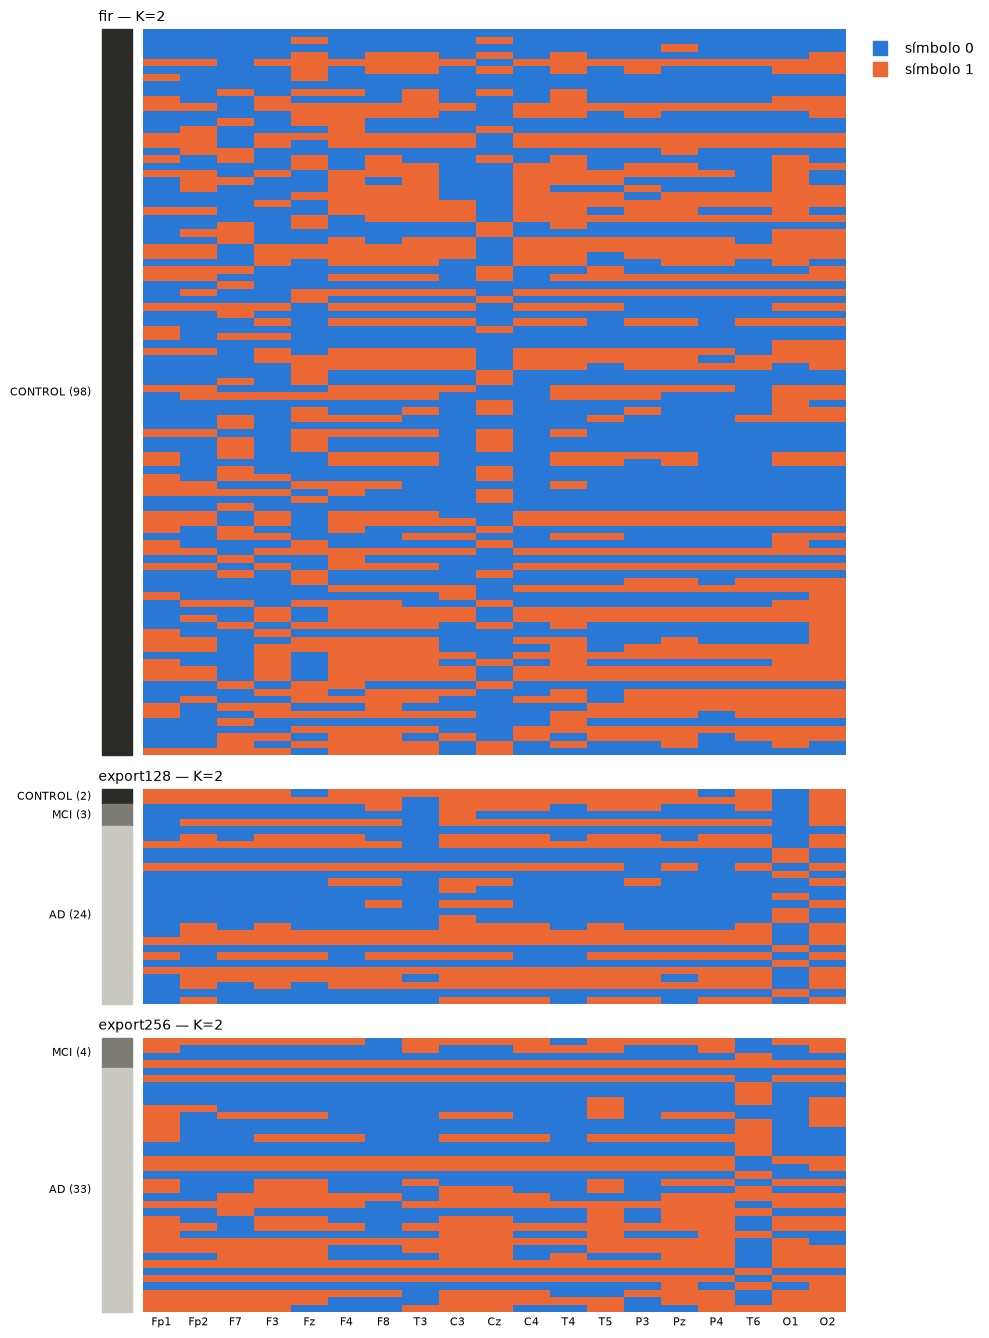

In [16]:
K_MAX_SEL = max(max(k.values()) for k in K_POR_CANAL.values())
cmap_k = ListedColormap([cor_grupo(v) for v in range(K_MAX_SEL)])
alturas = [max(len(PACIENTES[p]), 20) for p in PASTAS]
fig, eixos = plt.subplots(len(PASTAS), 1, figsize=(10, 2 + 0.07 * sum(alturas)), gridspec_kw=dict(height_ratios=alturas))
for ax, pasta in zip(eixos, PASTAS):
    t = TABELA[pasta]
    ordem = t.loc[sorted(t.index, key=lambda p: (ESTADOS.index(t.loc[p, 'estado']), p))]
    ax.imshow(ordem[CANAIS].values, aspect='auto', cmap=cmap_k, vmin=-0.5, vmax=K_MAX_SEL - 0.5, interpolation='nearest')
    ini = 0
    for e in ESTADOS_PASTA[pasta]:
        n = int((ordem.estado == e).sum())
        ax.add_patch(Rectangle((-1.6, ini - 0.5), 0.8, n, color=CORES[e], clip_on=False))
        ax.text(-1.9, ini + n / 2 - 0.5, f'{e} ({n})', ha='right', va='center', fontsize=8)
        ini += n
    ax.set_xticks(range(len(CANAIS)), CANAIS if ax is eixos[-1] else [''] * len(CANAIS), fontsize=8)
    ax.set_yticks([]); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlim(-1.7, len(CANAIS) - 0.5)
    ax.set_title(f'{pasta} — {descrever_k(pasta)}', loc='left', fontsize=10)
alcas = [Line2D([], [], marker='s', ls='', markersize=10, color=cor_grupo(v), label=f'símbolo {v}') for v in range(K_MAX_SEL)]
eixos[0].legend(handles=alcas, loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout()
mostrar(fig, 'discretizacao')

### 2.6 As árvores com o corte aplicado

Uma figura por pasta: as 19 árvores com o seu K, os ramos cortados em vermelho e as faixas de estado e grupo à direita.
Cada pasta sai no seu desenho (`ESCALA_PASTA`), para comparar: `fir` como estava, `export128` em cladograma, `export256` em topológica.

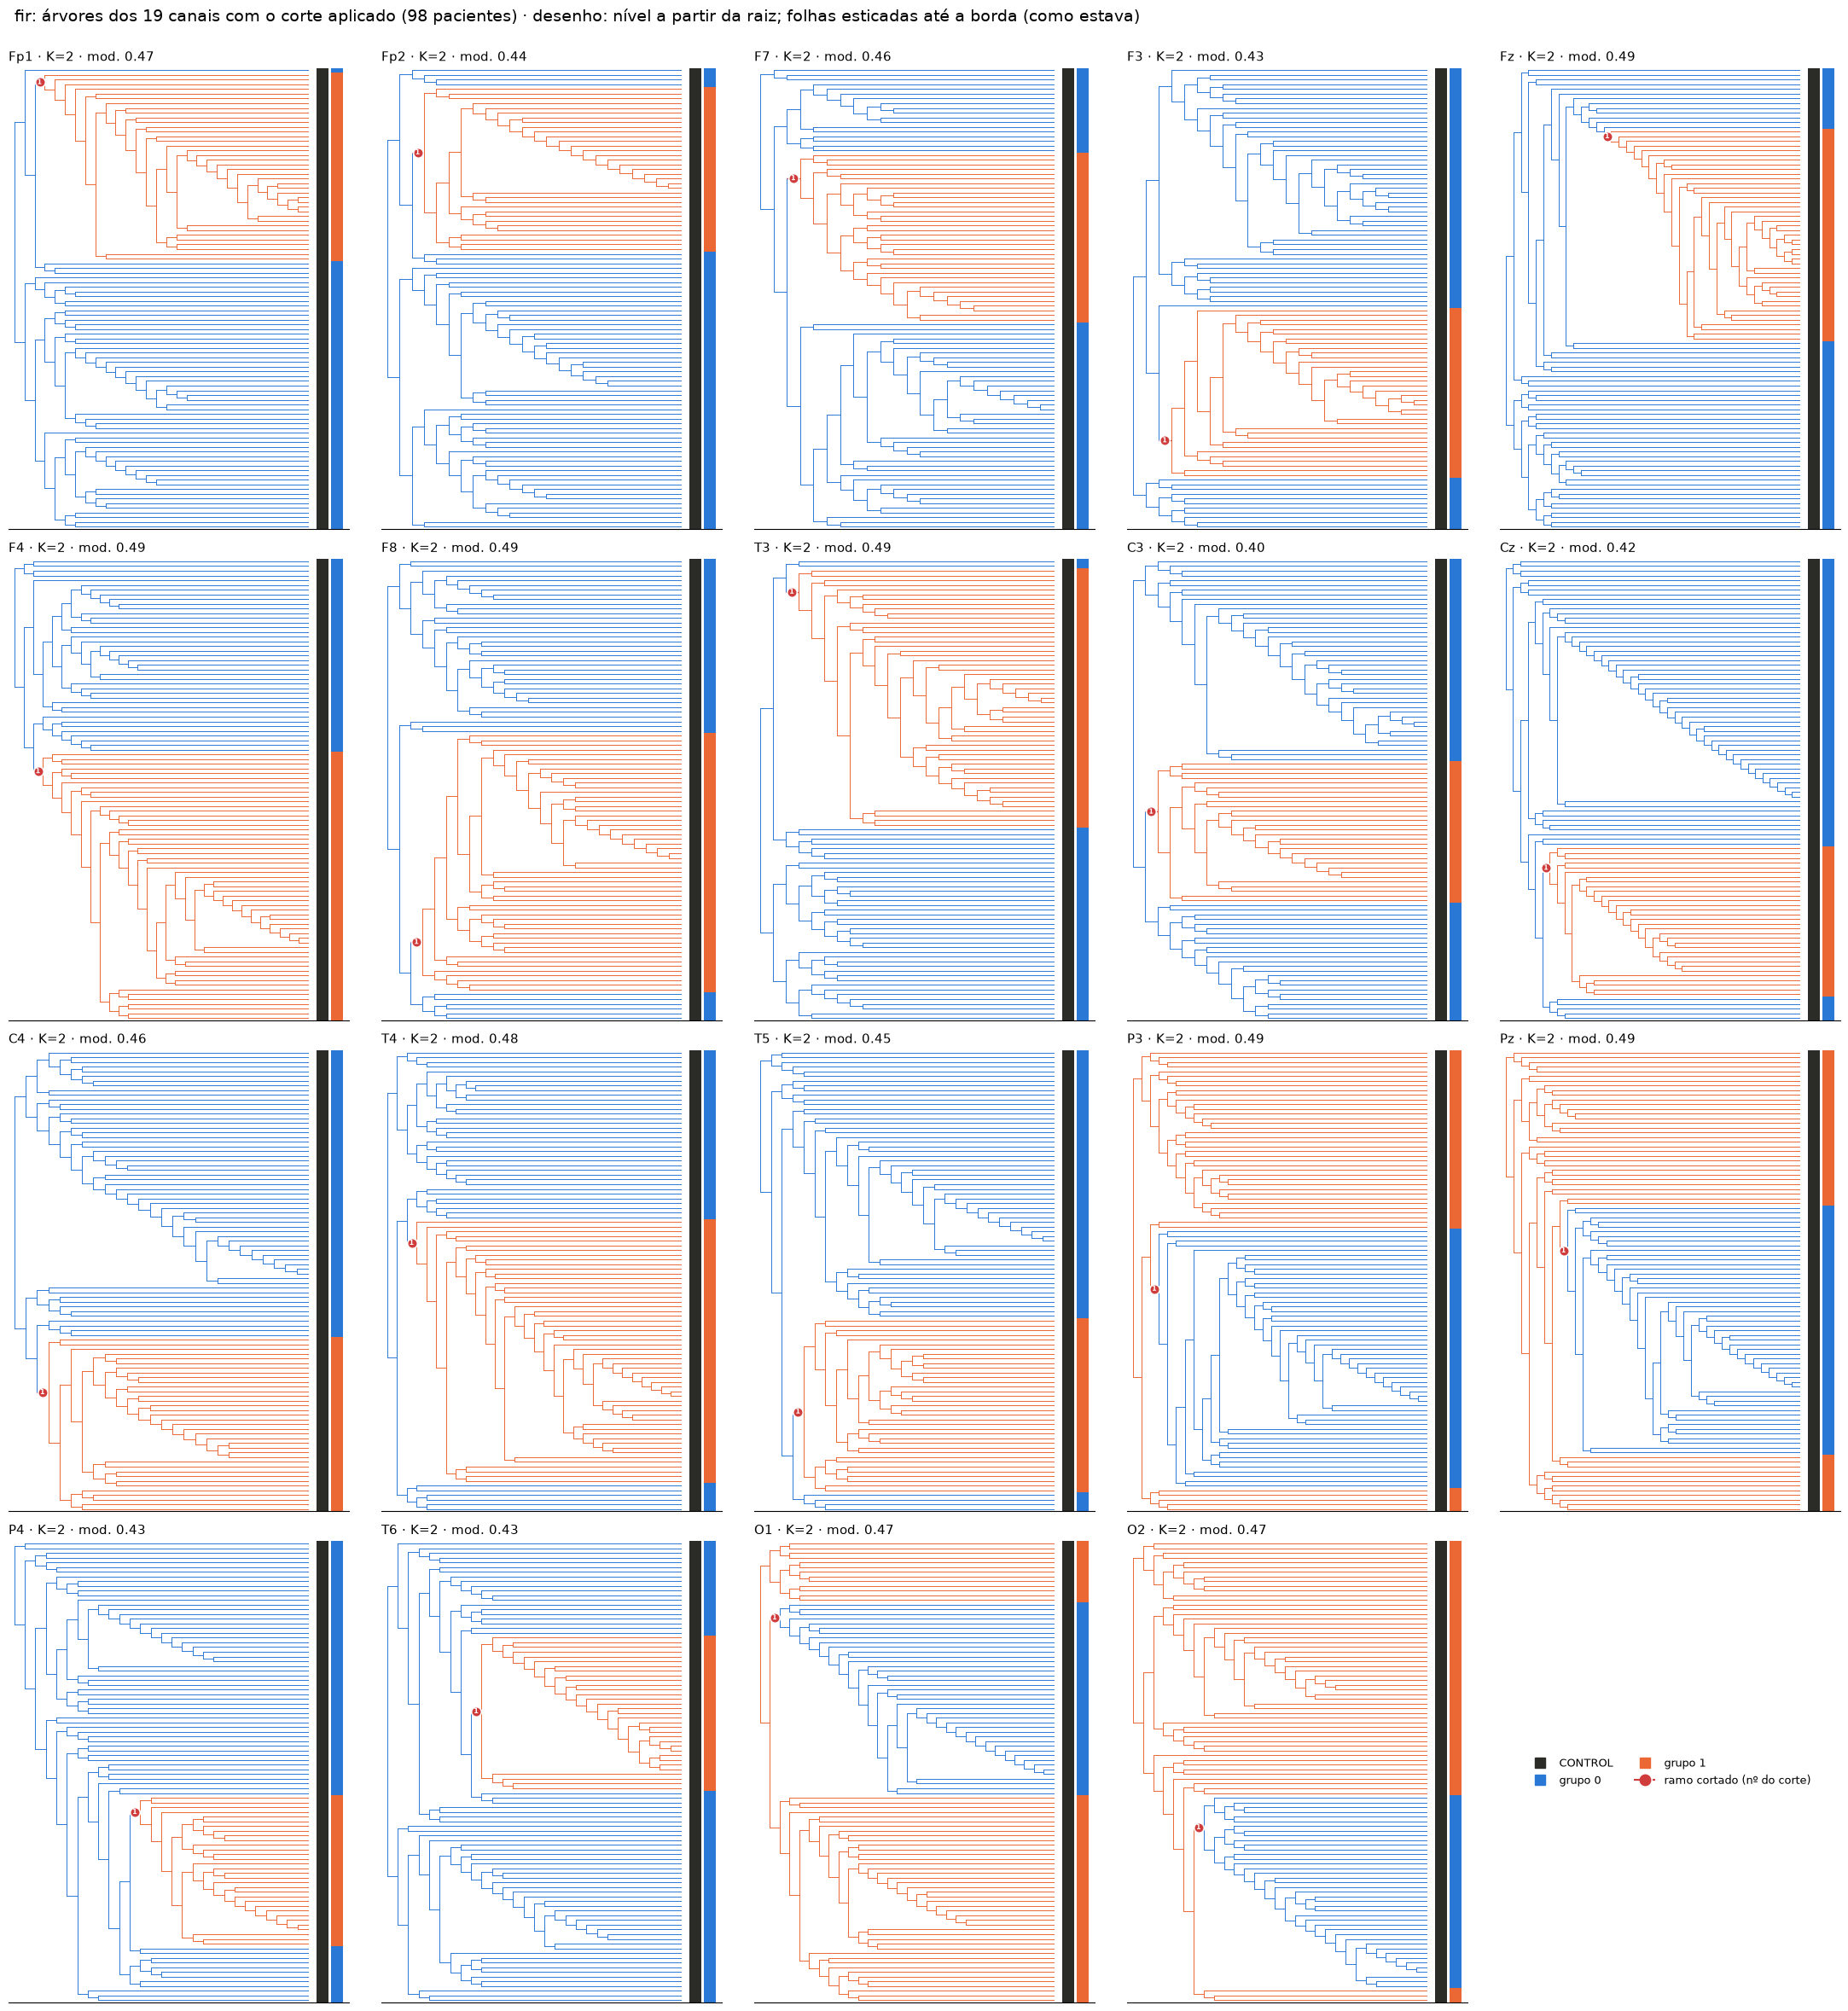

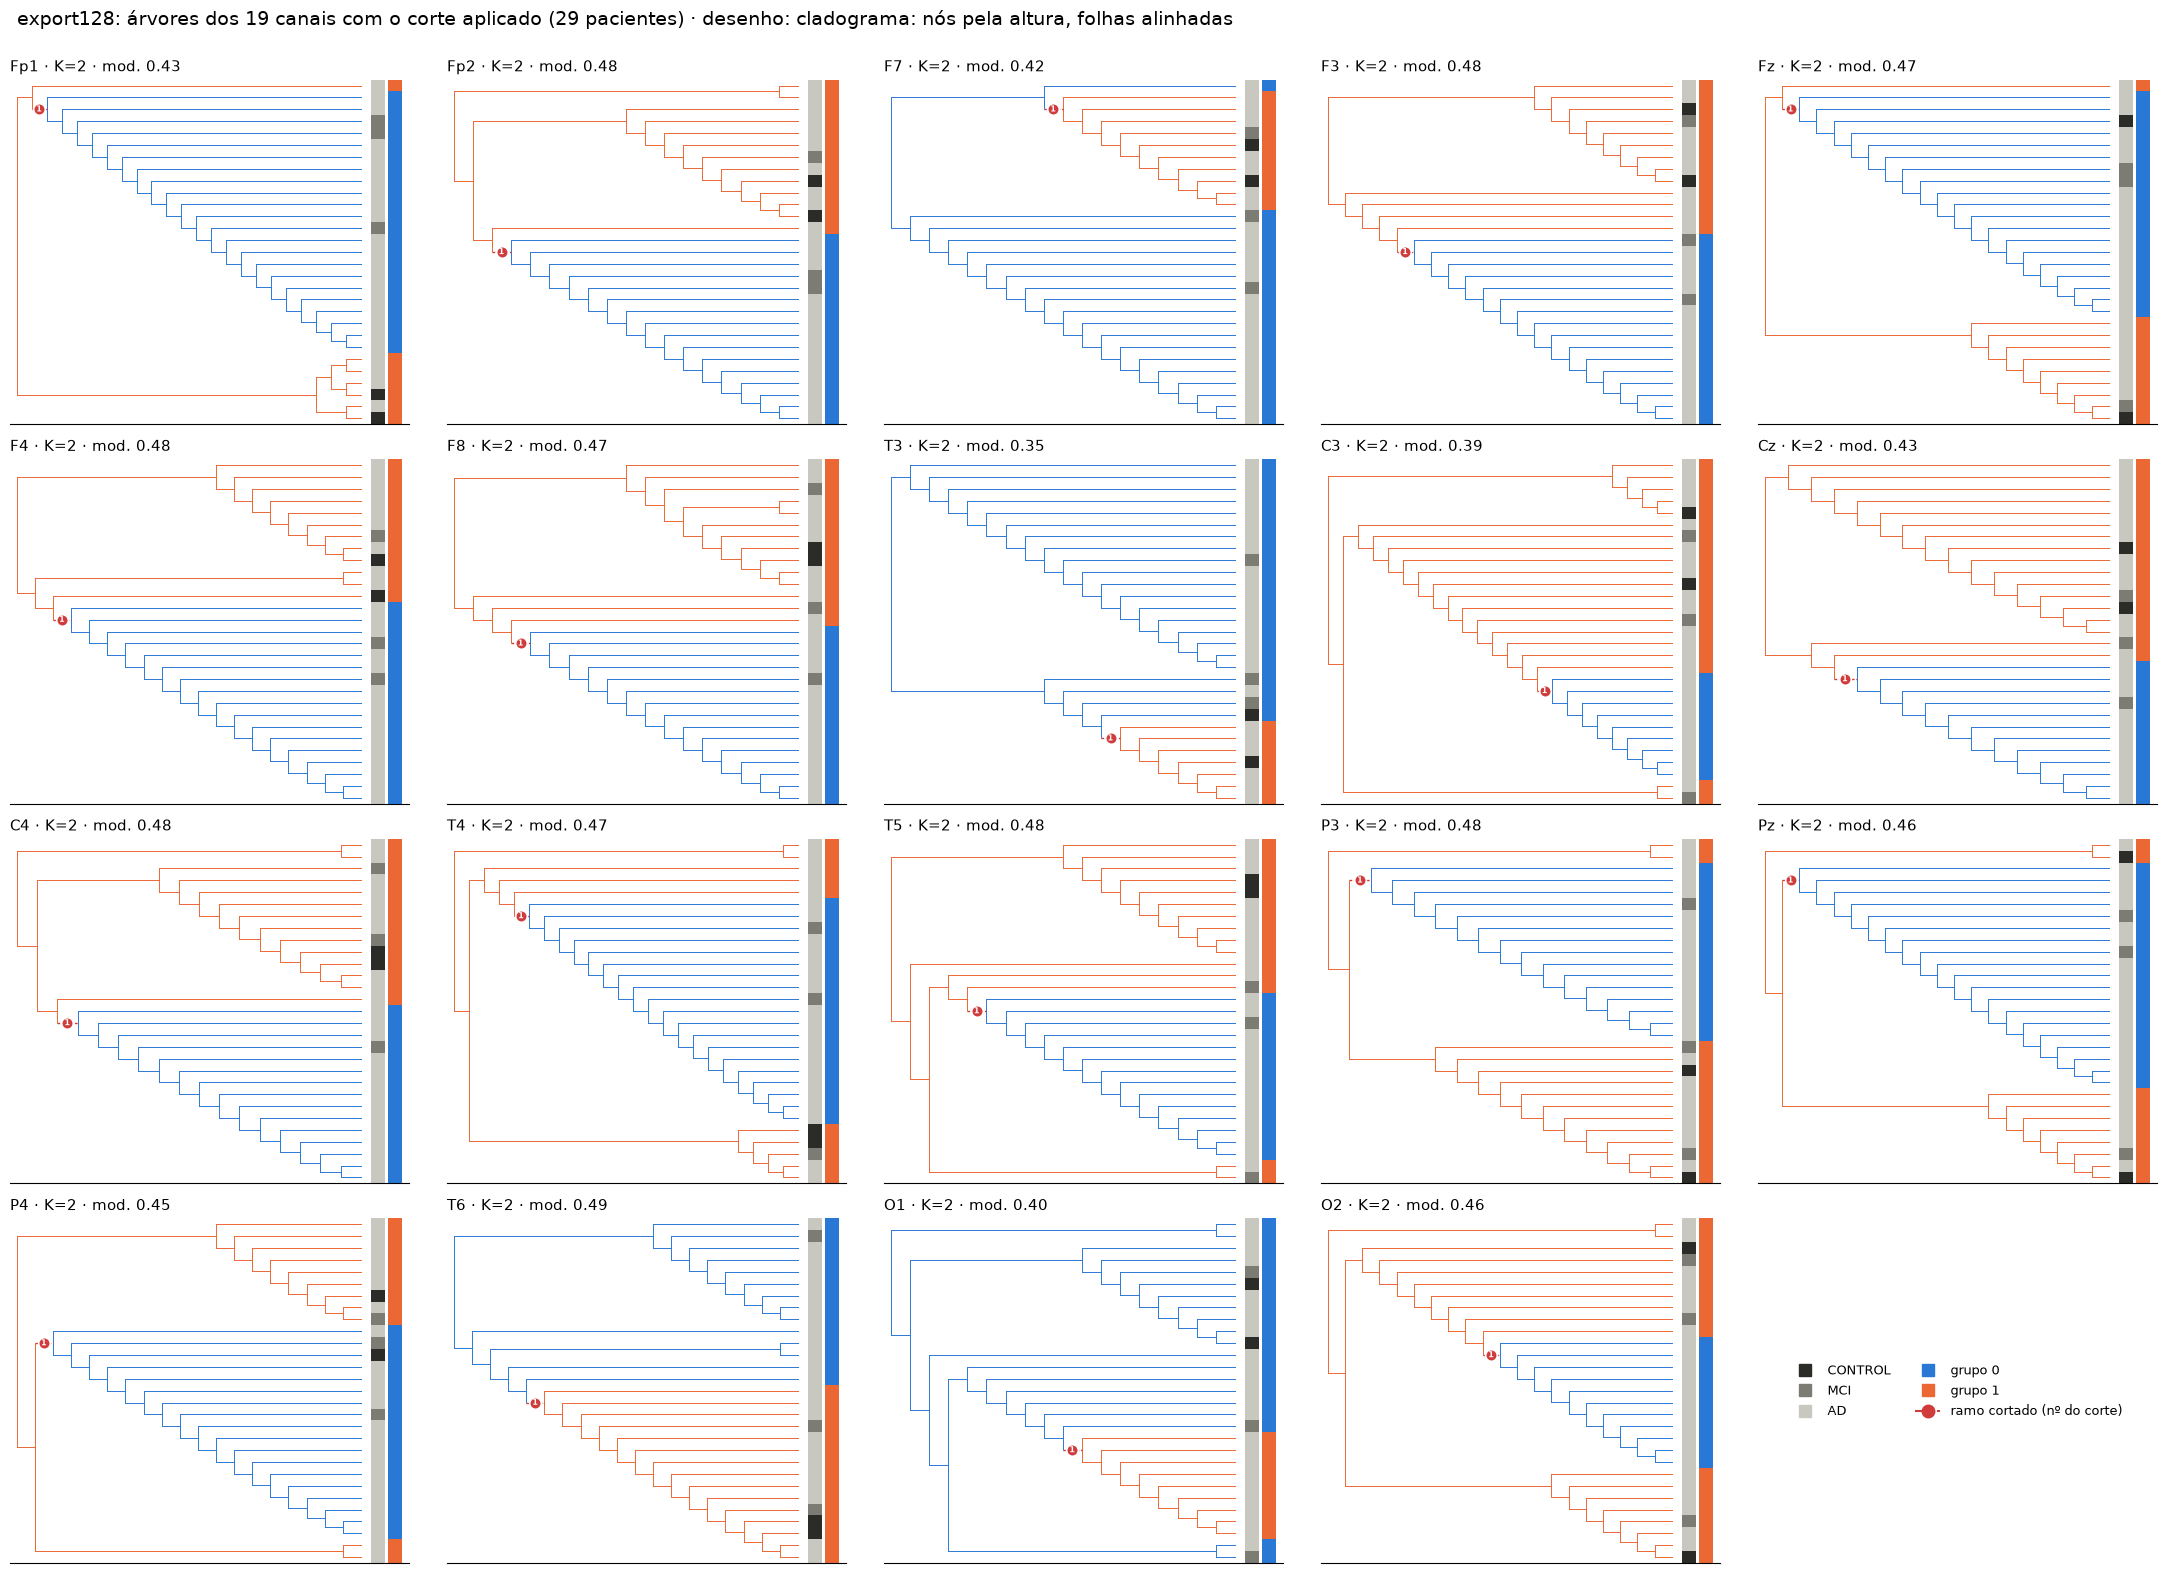

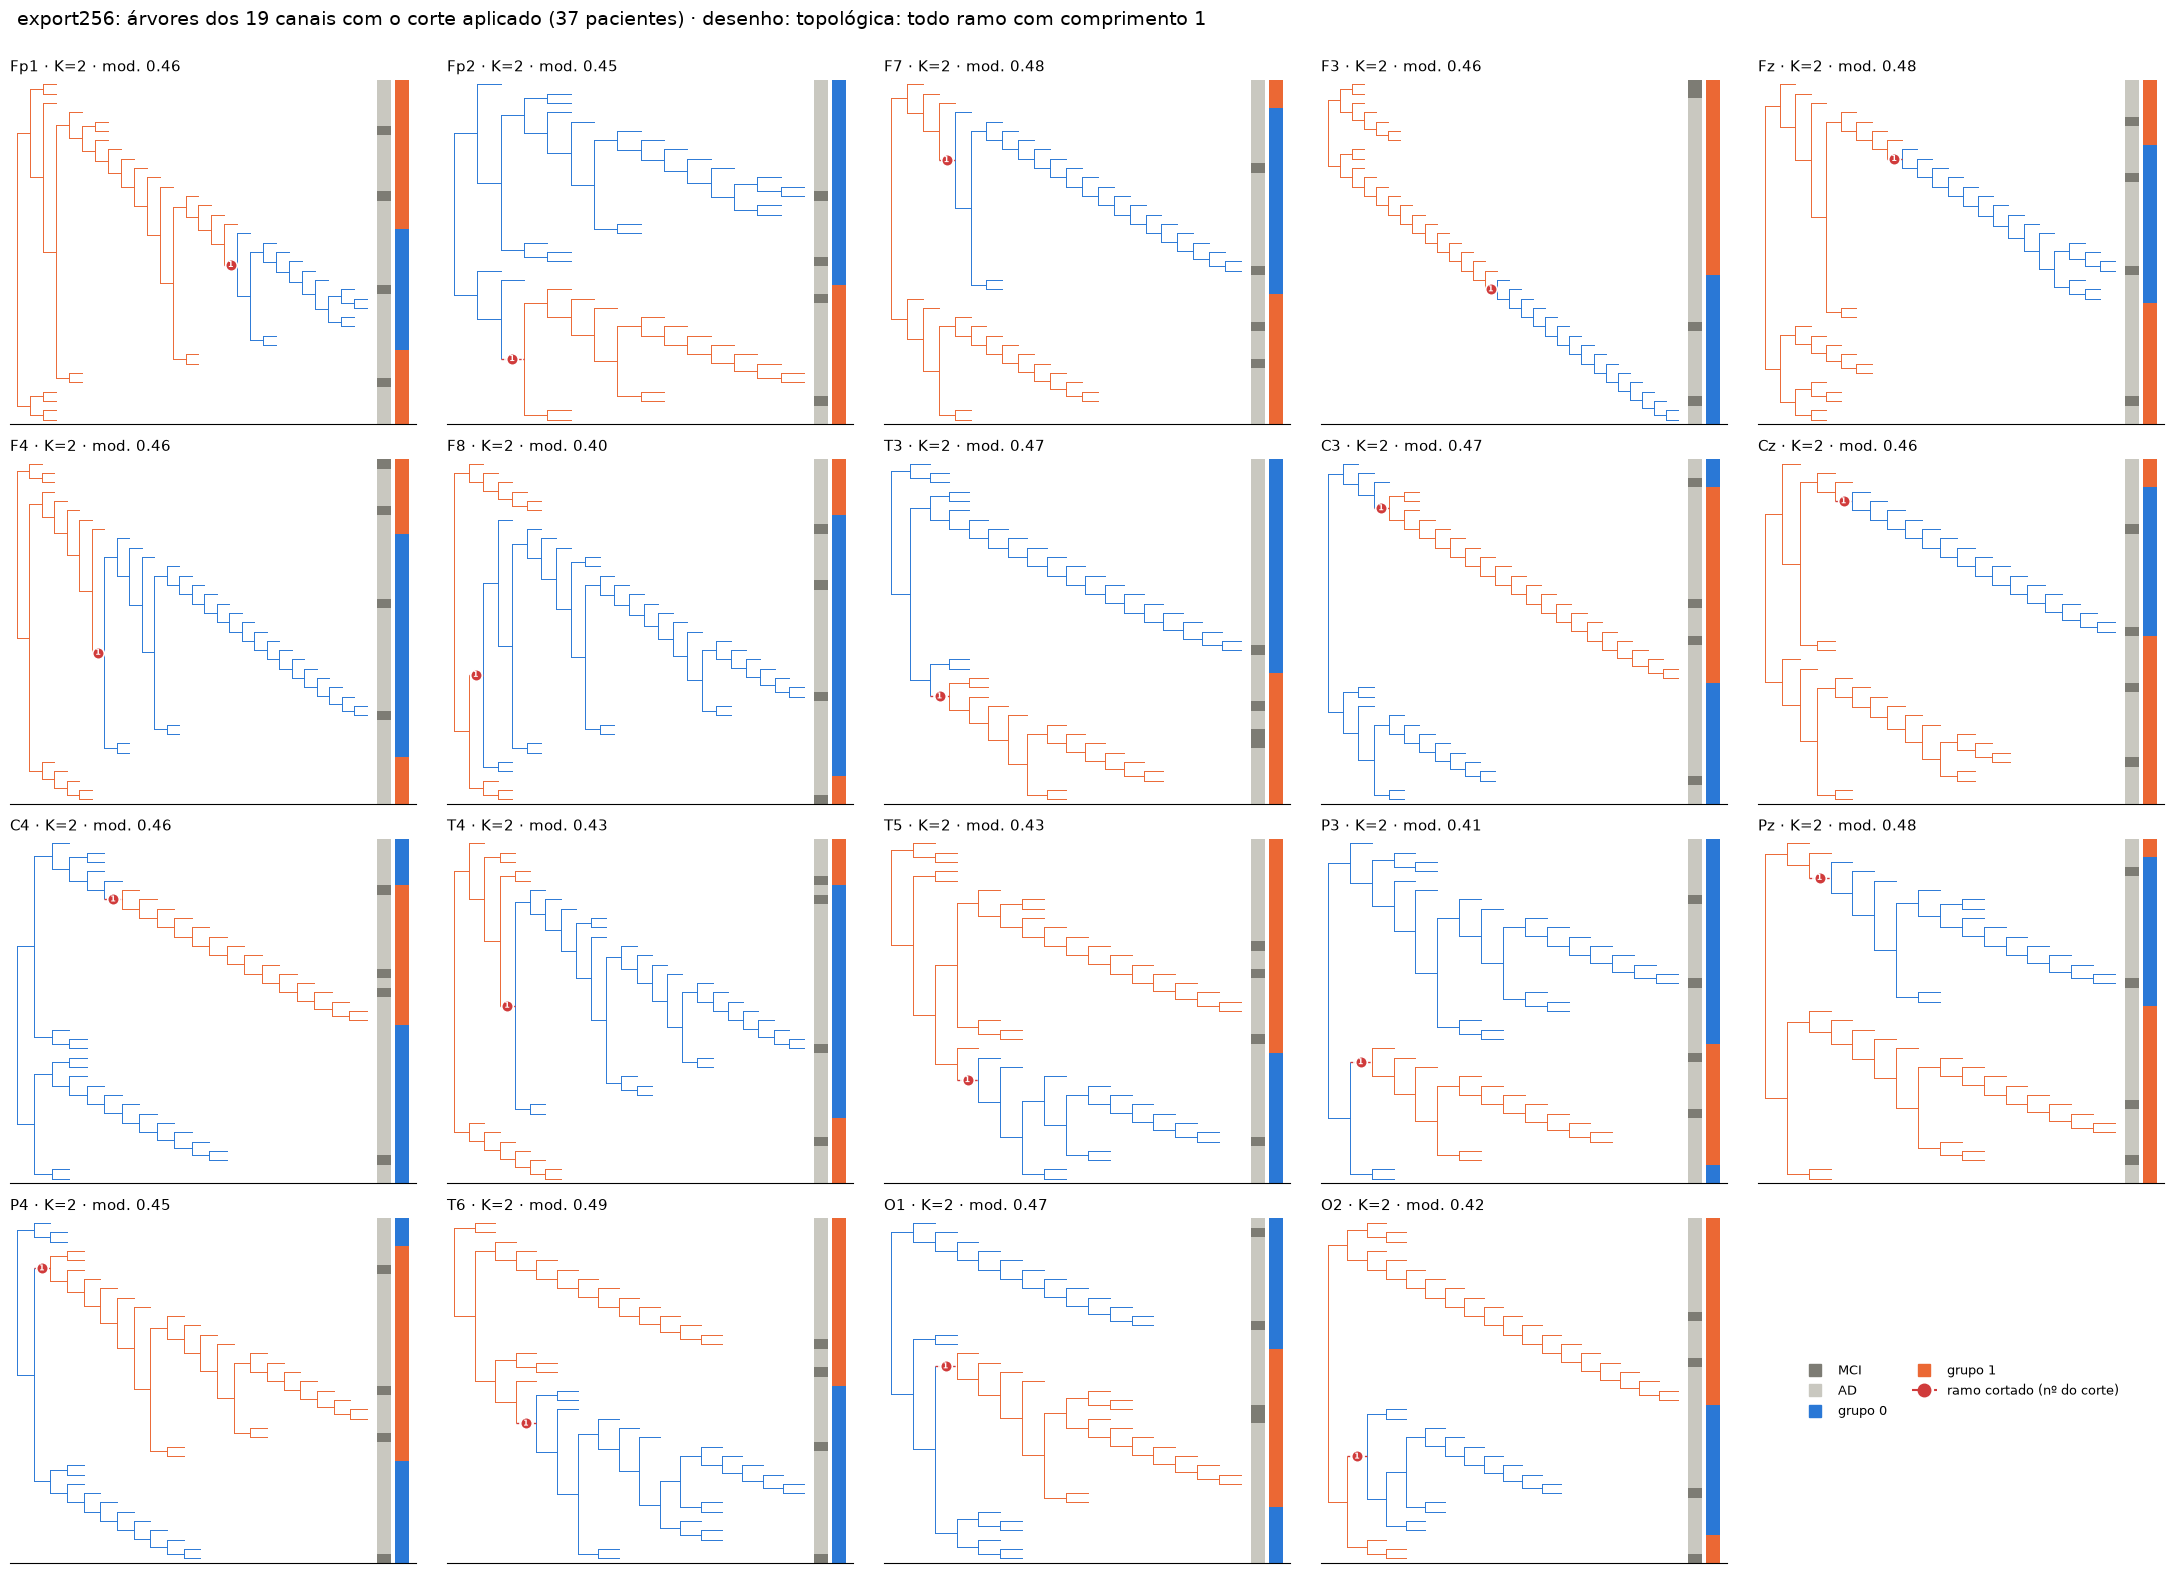

In [17]:
for pasta in PASTAS:
    fig, eixos = plt.subplots(4, 5, figsize=(22, 24 if len(PACIENTES[pasta]) > 50 else 16))
    for ax, canal in zip(eixos.flat, CANAIS):
        k = K_POR_CANAL[pasta][canal]
        desenhar_corte(ax, ARVORES[pasta, canal], k, compacto=True, escala=ESCALA_PASTA[pasta])
        ax.set_title(f'{canal} · K={k} · mod. {ARVORES[pasta, canal]["modularidade"][k]:.2f}', loc='left', fontsize=11)
    ax_leg = eixos.flat[len(CANAIS)]
    ax_leg.axis('off')
    legenda_corte(ax_leg, max(K_POR_CANAL[pasta].values()), ESTADOS_PASTA[pasta], dentro=True)
    fig.suptitle(f'{pasta}: árvores dos 19 canais com o corte aplicado ({len(PACIENTES[pasta])} pacientes) · desenho: '
                 f'{EIXO_ESCALA[ESCALA_PASTA[pasta]]}', x=0.01, ha='left', fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    mostrar(fig, f'arvores_{pasta}')

## 3. Passo 3 — Grupos de canais (estrutura do modelo)

Em cada pasta, o DAMICORE roda sobre a tabela de discretização com **cada canal (coluna) como objeto**: o objeto de um canal é a sequência dos símbolos
de todos os pacientes da pasta naquele canal. O FastGreedy reúne os canais que discretizaram os pacientes de modo parecido, com número de grupos automático.
O estado não entra: um modelo por pasta, com todos os pacientes.

**Canais idênticos** (mesma sequência) seriam objetos com NCD = 0, que o DAMICORE não aceita: só um representante entra, e os repetidos voltam ao grupo dele.

**Objetos pequenos:** o objeto de um canal tem um byte por paciente (dezenas nas pastas `export`), e com objetos desse tamanho o NCD é instável.

In [18]:
def damicore_tabela(pasta):
    dados = TABELA[pasta][CANAIS]
    representante, vistos = {}, {}
    for c in CANAIS:
        representante[c] = vistos.setdefault(tuple(dados[c]), c)
    unicos = list(dict.fromkeys(representante.values()))
    repetidos = {r: [c for c in CANAIS if representante[c] == r] for r in unicos}
    repetidos = {r: cs for r, cs in repetidos.items() if len(cs) > 1}
    dir_g = SAIDA_K[pasta] / 'grupos_canais'
    dir_g.mkdir(parents=True, exist_ok=True)
    if len(unicos) < 3:
        return {c: unicos.index(representante[c]) for c in CANAIS}, float('nan'), repetidos
    entrada = dir_g / 'entrada.csv'
    dados[unicos].to_csv(entrada, index=False)
    destino = dir_g / 'damicore'
    args = dict(source_kind='delimited', split='columns', compressor=COMPRESSOR_ESTRUTURA, num_clusters=None, output_dir=destino,
                keep_normalized=True, save_diagnostics=True, progress=False)
    try:
        r = run(entrada, **args)
    except (OutputDirectoryConflictError, DamicoreError) as e:
        if isinstance(e, DamicoreError) and not destino.exists():
            raise
        shutil.rmtree(destino)
        r = run(entrada, **args)
    r.close()
    rel = json.loads((destino / 'report.json').read_text(encoding='utf-8'))
    membros = pd.read_csv(destino / 'membership.csv').set_index('label')['cluster']
    return {c: int(membros[representante[c]]) for c in CANAIS}, rel['modularity'], repetidos

GRUPOS, MODULARIDADE, REPETIDOS = {}, {}, {}
for pasta in PASTAS:
    membros, MODULARIDADE[pasta], REPETIDOS[pasta] = damicore_tabela(pasta)
    GRUPOS[pasta] = {g: sorted([c for c in CANAIS if membros[c] == g], key=CANAIS.index) for g in sorted(set(membros.values()))}
    print(f'{pasta}: {len(GRUPOS[pasta])} grupos de canais, modularidade {MODULARIDADE[pasta]:.3f}')
    for g, cs in GRUPOS[pasta].items():
        print(f'   grupo {g}: {", ".join(cs)}')
    for cs in REPETIDOS[pasta].values():
        print(f'   canais idênticos (um só objeto): {", ".join(cs)}')

GRUPO_DO_CANAL = pd.DataFrame({p: {c: g for g, cs in GRUPOS[p].items() for c in cs} for p in PASTAS}).reindex(CANAIS)
pares = [(a, b) for i, a in enumerate(PASTAS) for b in list(PASTAS)[i + 1:]]
ARI_PASTAS = pd.Series({f'{a} × {b}': adjusted_rand_score(GRUPO_DO_CANAL[a], GRUPO_DO_CANAL[b]) for a, b in pares}, name='ARI')
print('\nARI entre os grupos de canais das pastas (1 = mesmos canais juntos, 0 = acaso):')
ARI_PASTAS.round(3).to_frame()

fir: 6 grupos de canais, modularidade 0.601
   grupo 0: Fp1, Fp2, F3
   grupo 1: F7, Fz, Cz
   grupo 2: F4, F8, T3, T4
   grupo 3: C3, C4, T5, P4
   grupo 4: P3, Pz, T6
   grupo 5: O1, O2
export128: 6 grupos de canais, modularidade 0.643
   grupo 0: Fp1, Fz, F4
   grupo 1: Fp2, F3, C4
   grupo 2: F7, T3, T4, Pz
   grupo 3: F8, Cz, O1, O2
   grupo 4: C3, T5, P3, T6
   grupo 5: P4
   canais idênticos (um só objeto): T5, T6


export256: 7 grupos de canais, modularidade 0.628
   grupo 0: Fp1, T3, T5
   grupo 1: Fp2, F8, T4, P3
   grupo 2: F7, C3, Cz, Pz, O2
   grupo 3: F3, Fz
   grupo 4: F4, C4
   grupo 5: P4, T6
   grupo 6: O1
   canais idênticos (um só objeto): C3, Cz

ARI entre os grupos de canais das pastas (1 = mesmos canais juntos, 0 = acaso):


,ARI
fir × export128,0.096
fir × export256,-0.043
export128 × export256,-0.055


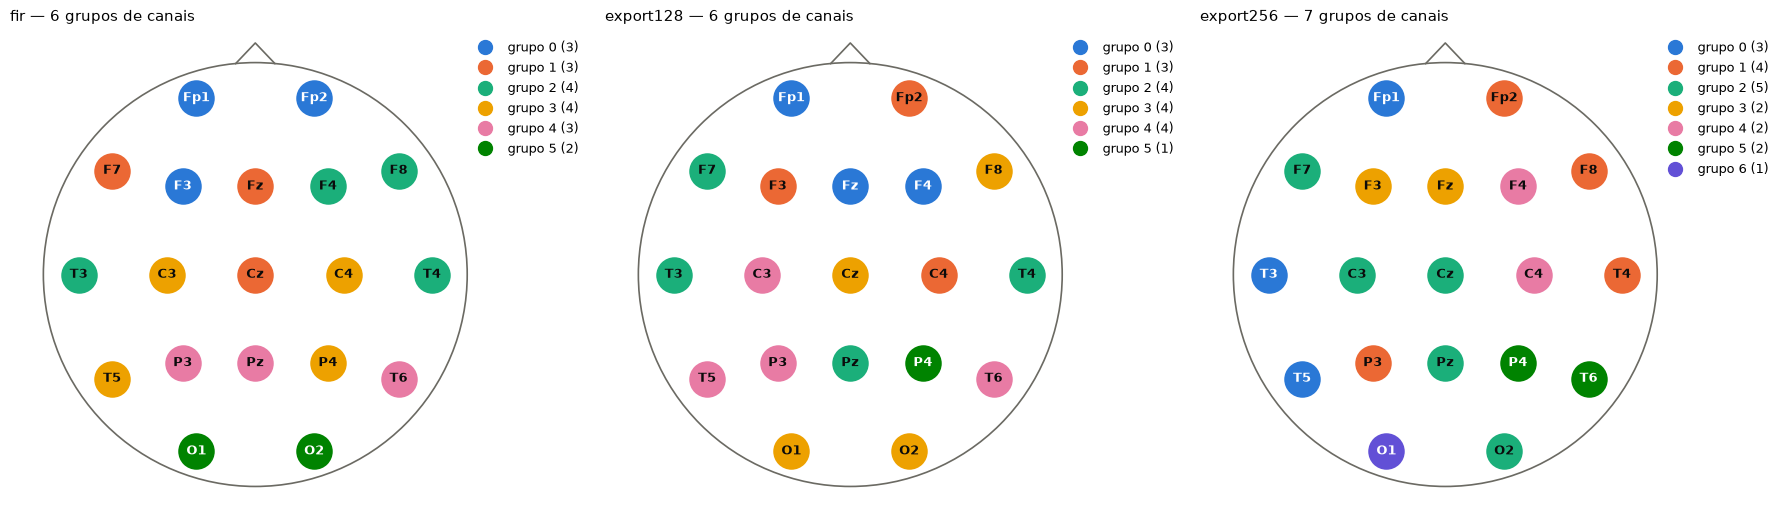

In [19]:
POSICOES = {'Fp1': (-0.3, 0.9), 'Fp2': (0.3, 0.9), 'F7': (-0.73, 0.53), 'F3': (-0.37, 0.45), 'Fz': (0, 0.45),
            'F4': (0.37, 0.45), 'F8': (0.73, 0.53), 'T3': (-0.9, 0), 'C3': (-0.45, 0), 'Cz': (0, 0), 'C4': (0.45, 0),
            'T4': (0.9, 0), 'T5': (-0.73, -0.53), 'P3': (-0.37, -0.45), 'Pz': (0, -0.45), 'P4': (0.37, -0.45),
            'T6': (0.73, -0.53), 'O1': (-0.3, -0.9), 'O2': (0.3, -0.9)}
TINTA_ESCURA = ('#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#17becf', '#bcbd22')

fig, eixos = plt.subplots(1, len(PASTAS), figsize=(18, 6))
for ax, pasta in zip(eixos, PASTAS):
    g = GRUPO_DO_CANAL[pasta]
    ax.add_patch(plt.Circle((0, 0), 1.08, fill=False, color='#6b6a63', lw=1.2))
    ax.plot([-0.1, 0, 0.1], [1.075, 1.18, 1.075], color='#6b6a63', lw=1.2)
    for canal, (px, py) in POSICOES.items():
        cor = cor_grupo(g[canal])
        ax.scatter(px, py, s=800, color=cor, edgecolor='white', linewidth=2, zorder=3)
        ax.text(px, py, canal, ha='center', va='center', fontsize=9, fontweight='bold', zorder=4,
                color='#0b0b0b' if cor in TINTA_ESCURA else '#ffffff')
    alcas = [Line2D([], [], marker='o', ls='', markersize=10, color=cor_grupo(k), label=f'grupo {k} ({(g == k).sum()})')
             for k in sorted(g.unique())]
    ax.legend(handles=alcas, loc='upper left', bbox_to_anchor=(0.92, 1), frameon=False, fontsize=9)
    ax.set_title(f'{pasta} — {g.nunique()} grupos de canais', loc='left', fontsize=11)
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.2, 1.25); ax.set_aspect('equal'); ax.axis('off')
fig.tight_layout()
mostrar(fig, 'escalpo')

## 4. Passo 4 — Tabelas de probabilidade (parâmetros do modelo)

Para cada pasta e cada grupo de canais, a **subtabela** é a tabela de discretização restrita aos canais do grupo, e cada linha é um **padrão** (ex.: `0 1 1 0`).
A tabela de probabilidade lista os padrões que aparecem:

- `contagem` e `probabilidade` = contagem / pacientes da pasta: os parâmetros do modelo;
- `prob_suavizada` = (contagem + `ALFA`) / (pacientes + `ALFA` · possíveis): a mesma probabilidade com Laplace, para avaliar padrões nunca vistos
  (usada quando os universos forem comparados). `possíveis` é o produto dos K dos canais do grupo;
- `n_CONTROL`, `n_MCI`, `n_AD`: quantos pacientes de cada estado têm o padrão. **São só rótulos**, não entram no modelo; mostram onde cada estado cai.

O modelo de cada pasta é o produto das tabelas dos seus grupos: $P(x) = \prod_g P_g(x_g)$, a mesma forma do ECGA (*marginal product model*).

A **ocupação** é a fração dos padrões possíveis que aparece. Quando `possíveis` passa do número de pacientes, a tabela não tem como ser completa
e o modelo fica esparso (aviso na coluna `aviso`).

In [20]:
def montar_modelo(pasta):
    dados = TABELA[pasta]
    modelo = {}
    for g, canais in GRUPOS[pasta].items():
        cont = dados[canais].value_counts()
        modelo[g] = dict(canais=canais, n=len(dados), possiveis=int(np.prod([K_POR_CANAL[pasta][c] for c in canais], dtype=float)),
                         contagens={tuple(int(v) for v in (p if isinstance(p, tuple) else (p,))): int(c) for p, c in cont.items()})
    return modelo

def tabela_probabilidade(pasta, g):
    item, dados = MODELO[pasta][g], TABELA[pasta]
    canais = item['canais']
    t = pd.crosstab([dados[c] for c in canais], dados.estado).reindex(columns=ESTADOS_PASTA[pasta], fill_value=0)
    t.columns = [f'n_{e}' for e in t.columns]
    t.insert(0, 'contagem', t.sum(axis=1))
    t.insert(1, 'probabilidade', t.contagem / item['n'])
    t.insert(2, 'prob_suavizada', (t.contagem + ALFA) / (item['n'] + ALFA * item['possiveis']))
    t = t.reset_index().sort_values(['contagem'] + canais, ascending=[False] + [True] * len(canais), ignore_index=True)
    t.index.name = 'padrao'
    return t

MODELO = {p: montar_modelo(p) for p in PASTAS}
linhas = []
for pasta in PASTAS:
    dir_p = SAIDA_K[pasta] / 'probabilidades'
    dir_p.mkdir(exist_ok=True)
    for g, item in MODELO[pasta].items():
        prob = tabela_probabilidade(pasta, g)
        TABELA[pasta][['estado'] + item['canais']].to_csv(dir_p / f'grupo{g}_subtabela.csv')
        prob.to_csv(dir_p / f'grupo{g}_probabilidade.csv')
        linhas.append(dict(pasta=pasta, grupo=g, canais=', '.join(item['canais']), n_canais=len(item['canais']),
                           pacientes=item['n'], padroes_vistos=len(prob), padroes_possiveis=item['possiveis'],
                           ocupacao=round(len(prob) / item['possiveis'], 4), prob_mais_comum=round(prob.probabilidade.iloc[0], 3),
                           aviso='possíveis > pacientes' if item['possiveis'] > item['n'] else ''))
RESUMO_TABELAS = pd.DataFrame(linhas).set_index(['pasta', 'grupo'])
print(f'{len(RESUMO_TABELAS)} tabelas de probabilidade em saida/<pasta>/<configuração>/probabilidades/')
RESUMO_TABELAS

19 tabelas de probabilidade em saida/<pasta>/<configuração>/probabilidades/


canais  n_canais  pacientes  padroes_vistos  padroes_possiveis  ocupacao  prob_mais_comum aviso
pasta     grupo                                                                                                             
fir       0            Fp1, Fp2, F3         3         98               8                  8    1.0000            0.398      
          1              F7, Fz, Cz         3         98               8                  8    1.0000            0.265      
          2          F4, F8, T3, T4         4         98              13                 16    0.8125            0.429      
          3          C3, C4, T5, P4         4         98              16                 16    1.0000            0.490      
          4              P3, Pz, T6         3         98               7                  8    0.8750            0.480      
          5                  O1, O2         2         98               4                  4    1.0000            0.500      
export128 0             Fp1, Fz, F4         3         29               6                  8    0.7500            0.552      
          1             Fp2, F3, C4         3         29               5                  8    0.6250            0.483      
          2          F7, T3, T4, Pz         4         29               6                 16    0.3750            0.621      
          3          F8, Cz, O1, O2         4         29               5                 16    0.3125            0.483      
          4          C3, T5, P3, T6         4         29               5                 16    0.3125            0.448      
          5                      P4         1         29               2                  2    1.0000            0.621      
export256 0             Fp1, T3, T5         3         37               5                  8    0.6250            0.378      
          1         Fp2, F8, T4, P3         4         37              10                 16    0.6250            0.486      
          2      F7, C3, Cz, Pz, O2         5         37              10                 32    0.3125            0.378      
          3                  F3, Fz         2         37               3                  4    0.7500            0.541      
          4                  F4, C4         2         37               3                  4    0.7500            0.595      
          5                  P4, T6         2         37               4                  4    1.0000            0.459      
          6                      O1         1         37               2                  2    1.0000            0.541

In [21]:
# Exemplo: a tabela do primeiro grupo de cada pasta (até 12 padrões)
for pasta in PASTAS:
    g, item = next(iter(MODELO[pasta].items()))
    print(f"=== {pasta} — grupo {g}: canais {item['canais']} | {item['n']} pacientes | "
          f"{len(item['contagens'])} de {item['possiveis']} padrões possíveis aparecem")
    display(tabela_probabilidade(pasta, g).head(12).round({'probabilidade': 4, 'prob_suavizada': 4}))

=== fir — grupo 0: canais ['Fp1', 'Fp2', 'F3'] | 98 pacientes | 8 de 8 padrões possíveis aparecem


,Fp1,Fp2,F3,contagem,probabilidade,prob_suavizada,n_CONTROL
padrao,,,,,,,
0,0,0,0,39,0.3980,0.3774,39
1,1,1,1,18,0.1837,0.1792,18
2,0,0,1,9,0.0918,0.0943,9
3,0,1,0,8,0.0816,0.0849,8
4,1,0,0,8,0.0816,0.0849,8
5,1,0,1,7,0.0714,0.0755,7
6,1,1,0,7,0.0714,0.0755,7
7,0,1,1,2,0.0204,0.0283,2


=== export128 — grupo 0: canais ['Fp1', 'Fz', 'F4'] | 29 pacientes | 6 de 8 padrões possíveis aparecem


,Fp1,Fz,F4,contagem,probabilidade,prob_suavizada,n_CONTROL,n_MCI,n_AD
padrao,,,,,,,,,
0,0,0,0,16,0.5517,0.4595,0,2,14
1,1,1,1,5,0.1724,0.1622,1,0,4
2,0,1,1,4,0.1379,0.1351,0,1,3
3,0,0,1,2,0.0690,0.0811,0,0,2
4,1,0,1,1,0.0345,0.0541,1,0,0
5,1,1,0,1,0.0345,0.0541,0,0,1


=== export256 — grupo 0: canais ['Fp1', 'T3', 'T5'] | 37 pacientes | 5 de 8 padrões possíveis aparecem


,Fp1,T3,T5,contagem,probabilidade,prob_suavizada,n_MCI,n_AD
padrao,,,,,,,,
0,1,1,1,14,0.3784,0.3333,3,11
1,0,0,0,11,0.2973,0.2667,1,10
2,1,0,1,7,0.1892,0.1778,0,7
3,1,0,0,3,0.0811,0.0889,0,3
4,0,0,1,2,0.0541,0.0667,0,2


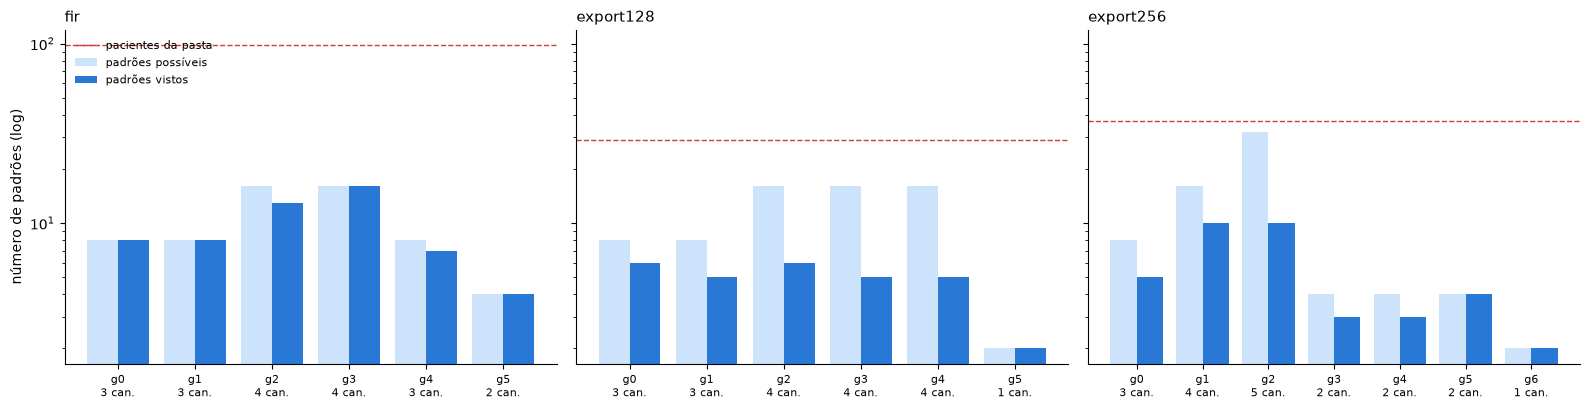

In [22]:
# Padrões vistos × possíveis em cada grupo (escala log): a distância entre as barras é a esparsidade
fig, eixos = plt.subplots(1, len(PASTAS), figsize=(16, 4.2), sharey=True)
for ax, pasta in zip(eixos, PASTAS):
    r = RESUMO_TABELAS.loc[pasta]
    x = np.arange(len(r))
    ax.bar(x - 0.2, r.padroes_possiveis, 0.4, color='#cde2fb', label='padrões possíveis')
    ax.bar(x + 0.2, r.padroes_vistos, 0.4, color='#2a78d6', label='padrões vistos')
    ax.axhline(len(PACIENTES[pasta]), color='#d03b3b', lw=1, ls='--', label='pacientes da pasta')
    ax.set_yscale('log')
    ax.set_xticks(x, [f'g{g}\n{n} can.' for g, n in zip(r.index, r.n_canais)], fontsize=8)
    ax.set_title(pasta, loc='left', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)
eixos[0].set_ylabel('número de padrões (log)')
eixos[0].legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout()
mostrar(fig, 'ocupacao')

## 5. Relatório da execução

Um arquivo HTML único (figuras embutidas) em `saida/relatorios/`, com a configuração, os números de cada pasta, as figuras e as ressalvas.
O nome traz a configuração (`K2` quando todas as pastas usam K=2 sem ajustes). Cada execução também grava um `metricas_<configuração>.json`,
e o relatório monta uma tabela com todas as configurações já executadas.

In [23]:
DIR_RELATORIOS = SAIDA / 'relatorios'
DIR_RELATORIOS.mkdir(exist_ok=True)
agora = datetime.now()
esc = html.escape
CONFIG_GERAL = ((next(iter(CONFIG.values())) if len(set(CONFIG.values())) == 1
                 else 'K_' + '_'.join(f'{p}-{CONFIG[p]}' for p in PASTAS)) + '_' + '-'.join(COMPRESSOR[p] for p in PASTAS))

POR_PASTA = pd.DataFrame({p: {
    'pacientes': len(PACIENTES[p]),
    'estados': ', '.join(f"{int((TABELA[p].estado == e).sum())} {e}" for e in ESTADOS_PASTA[p]),
    'compressor': COMPRESSOR[p],
    'K': descrever_k(p),
    'k automático (mín–máx)': f"{EXECUCOES.loc[p, 'k_automatico'].min()}–{EXECUCOES.loc[p, 'k_automatico'].max()}",
    'grupos de canais': len(GRUPOS[p]),
    'maior grupo (canais)': max(len(cs) for cs in GRUPOS[p].values()),
    'modularidade (canais)': round(MODULARIDADE[p], 3),
    'ocupação média': round(RESUMO_TABELAS.loc[p, 'ocupacao'].mean(), 3),
    'tabelas com possíveis > pacientes': int((RESUMO_TABELAS.loc[p, 'aviso'] != '').sum()),
} for p in PASTAS})

metricas = dict(config=CONFIG_GERAL, damicore=damicore.__version__, compressor=COMPRESSOR, compressor_estrutura=COMPRESSOR_ESTRUTURA, data=agora.isoformat(timespec='seconds'), k_discretizacao=K_DISCRETIZACAO,
                k_por_canal=K_POR_CANAL, ajustes=AJUSTADOS, n_amostras=N_AMOSTRAS,
                pacientes={p: len(PACIENTES[p]) for p in PASTAS}, retirados=RETIRADOS.paciente.tolist(),
                grupos_canais={p: {str(g): cs for g, cs in GRUPOS[p].items()} for p in PASTAS},
                modularidade_canais=MODULARIDADE, ari_pastas=ARI_PASTAS.to_dict(),
                ocupacao_media={p: float(RESUMO_TABELAS.loc[p, 'ocupacao'].mean()) for p in PASTAS})
(DIR_RELATORIOS / f'metricas_{CONFIG_GERAL}.json').write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding='utf-8')

comparativo = []
for f in sorted(DIR_RELATORIOS.glob('metricas_*.json')):
    d = json.loads(f.read_text(encoding='utf-8'))
    for p in PASTAS:
        comparativo.append({'configuração': d['config'], 'executado em': d['data'].replace('T', ' ')[:16], 'pasta': p,
                            'compressor': d.get('compressor', {}).get(p, 'zlib'), 'K da caixa': d['k_discretizacao'][p], 'ajustes': len(d['ajustes'][p]),
                            'grupos de canais': len(d['grupos_canais'][p]), 'ocupação média': round(d['ocupacao_media'][p], 3)})
COMPARATIVO = pd.DataFrame(comparativo).set_index(['configuração', 'pasta'])

def tab(df, indice=True):
    return df.to_html(classes='tabela', border=0, index=indice, na_rep='', float_format=lambda v: f'{v:.3f}')

def fig_html(nome, legenda):
    if nome not in FIGURAS:
        return ''
    return f'<figure><img src="data:image/png;base64,{FIGURAS[nome]}" alt="{esc(legenda)}"><figcaption>{esc(legenda)}</figcaption></figure>'

CSS = """
:root{--fundo:#ffffff;--texto:#1f1f1c;--suave:#5f5e57;--linha:#e3e2dc;--painel:#f6f6f3;--destaque:#2a78d6;--escolha:#1a7f4b}
*{box-sizing:border-box}
body{margin:0;background:var(--fundo);color:var(--texto);font:15px/1.55 system-ui,-apple-system,'Segoe UI',Roboto,sans-serif}
main{max-width:1080px;margin:0 auto;padding:32px 16px 64px}
h1{font-size:28px;margin:0 0 4px}
h2{font-size:20px;margin:40px 0 8px;padding-top:16px;border-top:1px solid var(--linha)}
h3{font-size:16px;margin:24px 0 6px}
p,li{max-width:80ch}
.sub{color:var(--suave);margin:0 0 20px}
.config{display:flex;flex-wrap:wrap;gap:8px;margin:12px 0 24px}
.config span{background:var(--painel);border:1px solid var(--linha);border-radius:999px;padding:3px 12px;font-size:13px}
.rolagem{overflow-x:auto}
table.tabela{border-collapse:collapse;font-size:13px;margin:8px 0 16px;font-variant-numeric:tabular-nums}
table.tabela th,table.tabela td{border-bottom:1px solid var(--linha);padding:4px 10px;text-align:left;vertical-align:top}
table.tabela thead th{background:var(--painel)}
figure{margin:16px 0}
figure img{max-width:100%;height:auto;border:1px solid var(--linha);border-radius:8px}
figcaption{font-size:13px;color:var(--suave);margin-top:4px}
code{background:var(--painel);padding:0 4px;border-radius:4px}
@media print{main{max-width:none;padding:0}figure{break-inside:avoid}}
"""

retirados_txt = '; '.join(f'{r.paciente} ({r.pasta}, {r.motivo})' for r in RETIRADOS.itertuples()) or 'nenhum'
grupos_df = pd.DataFrame([dict(pasta=p, grupo=g, canais=', '.join(cs), n_canais=len(cs)) for p in PASTAS for g, cs in GRUPOS[p].items()])
repetidos_txt = '; '.join(f'{p}: ' + ' | '.join(', '.join(cs) for cs in REPETIDOS[p].values()) for p in PASTAS if REPETIDOS[p])
arvores_html = ''.join(fig_html(f'arvores_{p}', f'{p}: árvores dos 19 canais com o corte aplicado, desenho {NOME_ESCALA[ESCALA_PASTA[p]]}; '
                                  'faixas à direita = estado (rótulo) e grupo.') for p in PASTAS)
cortes_html = ''.join(f'<h3>{p}</h3><div class="rolagem">{tab(CORTE[p])}</div>' for p in PASTAS)

RESSALVAS = f"""<ul>
<li><b>Sem contraste de estado dentro das pastas.</b> A pasta fir só tem controles; as pastas export, {esc(POR_PASTA.loc['estados', 'export128'])} e {esc(POR_PASTA.loc['estados', 'export256'])}.
Os modelos descrevem cada universo; comparar estados depende de juntar os universos.</li>
<li><b>Pastas export pequenas.</b> Com {len(PACIENTES['export128'])} e {len(PACIENTES['export256'])} pacientes, o objeto de um canal no passo 3 tem esse número de bytes,
e o NCD é instável com objetos tão pequenos. As tabelas de probabilidade dessas pastas ficam esparsas mesmo com K=2.</li>
<li><b>Sinais originais.</b> Sem reamostragem e sem filtro. A pasta export256 chega sem delta (filtro do aparelho); a escala e o alfabeto diferem entre as pastas,
o que só importa ao juntá-las.</li>
<li><b>Janela.</b> {N_AMOSTRAS} amostras: 30 s nas pastas de 128 Hz e 15 s na de 256 Hz.</li>
<li><b>Rótulos dos grupos.</b> O número de um grupo não tem o mesmo significado de um canal para outro, nem de uma pasta para outra.</li>
{f'<li><b>Canais idênticos no passo 3</b> entraram como um só objeto: {esc(repetidos_txt)}.</li>' if repetidos_txt else ''}
{('<li><b>K ajustados à mão</b> em alguns canais (painel ou K_MANUAL): ' + esc('; '.join(f'{p}: ' + ', '.join(f'{c}={k}' for c, k in a.items()) for p, a in AJUSTADOS.items() if a)) + '.</li>') if any(AJUSTADOS.values()) else ''}
</ul>"""

relatorio = f"""<!doctype html>
<html lang="pt-BR"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>DAMICORE v4 — {CONFIG_GERAL}</title><style>{CSS}</style></head>
<body><main>
<h1>DAMICORE v4: um universo por equipamento <span style="color:var(--suave);font-weight:400">· {esc(CONFIG_GERAL)}</span></h1>
<p class="sub">Discretização, estrutura e tabelas de probabilidade em cada pasta de equipamento · gerado em {agora:%d/%m/%Y %H:%M} ·
as decisões que levaram a esta configuração estão em <a href="decisoes.html">decisoes.html</a></p>
<div class="config">{''.join(f'<span>{p}: {esc(descrever_k(p))}</span>' for p in PASTAS)}<span>compressor: {esc(', '.join(f'{p} {COMPRESSOR[p]}' for p in PASTAS))}; passo 3 {COMPRESSOR_ESTRUTURA}</span><span>damicore {damicore.__version__}</span><span>{N_AMOSTRAS} amostras por objeto</span>
<span>sinais originais, sem reamostrar nem filtrar</span><span>um modelo por pasta · estados como rótulo</span></div>

<h2>Resumo por pasta</h2>
<div class="rolagem">{tab(POR_PASTA)}</div>

<h2>Compressor</h2>
<p>Os quatro compressores da 0.5.0 foram testados nos objetos do V4 (testes/teste_compressores.py), com critérios aplicados nesta ordem: validade,
identificação do mesmo paciente em duas janelas, estabilidade do corte K=2 e custo. Escolhidos: {esc(', '.join(f'{p} {COMPRESSOR[p]}' for p in PASTAS))}.</p>
{tab(RESUMO_TESTE) if RESUMO_TESTE is not None else ''}
{fig_html('compressores', 'Teste dos compressores, média de 5 canais por pasta.')}

<h2>1. Objetos</h2>
<p>{len(ORGANIZACAO)} pacientes copiados dos brutos e separados por equipamento. Retirados: {esc(retirados_txt)}.
Cada canal de cada paciente é um objeto de {N_AMOSTRAS} valores float32 ({BYTES_OBJETO} bytes), com os valores originais.</p>
{fig_html('sinais', 'Canal P3, 4 s, de um paciente de cada pasta (valores originais).')}

<h2>2. Discretização</h2>
<p>O DAMICORE rodou em cada canal de cada pasta (NCD → árvore NJ), sem usar o estado. Cada árvore foi cortada no K da caixa de discretização
(com os ajustes por canal, se houver), e o grupo de cada paciente é o seu símbolo naquele canal.</p>
{fig_html('discretizacao', 'Tabelas de discretização: pacientes × canais, cor = símbolo; faixa à esquerda = estado (rótulo).')}
{fig_html('mapa_k', 'Modularidade de cada corte, por pasta, canal e K.')}
{cortes_html}
{arvores_html}

<h2>3. Grupos de canais</h2>
<p>Em cada pasta, o DAMICORE rodou sobre a tabela de discretização com os canais como objetos (número de grupos automático).
Canais do mesmo grupo dividem os pacientes de modo parecido e são tratados como dependentes no modelo.</p>
{tab(grupos_df, indice=False)}
<p>ARI entre os grupos de canais das pastas (1 = mesma estrutura, 0 = acaso): {esc('; '.join(f'{k} {v:.3f}' for k, v in ARI_PASTAS.items()))}.</p>
{fig_html('escalpo', 'Grupos de canais de cada pasta na posição dos eletrodos (10-20, nariz para cima).')}

<h2>4. Tabelas de probabilidade</h2>
<p>Uma tabela por grupo de canais: os padrões que aparecem e a sua frequência. O modelo de cada pasta é P(x) = ∏ P<sub>g</sub>(x<sub>g</sub>).
Ocupação = padrões vistos / possíveis. As tabelas completas estão em <code>saida/&lt;pasta&gt;/&lt;configuração&gt;/probabilidades/</code>.</p>
<div class="rolagem">{tab(RESUMO_TABELAS)}</div>
{fig_html('ocupacao', 'Padrões possíveis × vistos em cada grupo de canais (log); linha vermelha = pacientes da pasta.')}

<h2>Ressalvas</h2>
{RESSALVAS}

<h2>Configurações já executadas</h2>
<div class="rolagem">{tab(COMPARATIVO)}</div>
</main></body></html>"""

ARQUIVO_RELATORIO = DIR_RELATORIOS / f'relatorio_{CONFIG_GERAL}.html'
ARQUIVO_RELATORIO.write_text(relatorio, encoding='utf-8')
print(f'Relatório: {ARQUIVO_RELATORIO} ({ARQUIVO_RELATORIO.stat().st_size / 1024:.0f} KB)')
POR_PASTA

Relatório: C:\DAMICORE\DAMICORE_v4\saida\relatorios\relatorio_K2_zlib-ppmd-ppmd.html (1071 KB)


,fir,export128,export256
pacientes,98,29,37
estados,98 CONTROL,"2 CONTROL, 3 MCI, 24 AD","4 MCI, 33 AD"
compressor,zlib,ppmd,ppmd
K,K=2,K=2,K=2
k automático (mín–máx),11–15,6–8,7–9
grupos de canais,6,6,7
maior grupo (canais),4,4,5
modularidade (canais),0.601,0.643,0.628
ocupação média,0.948,0.562,0.723
tabelas com possíveis > pacientes,0,0,0


## 6. Relatório de decisões

O arquivo `decisoes.yaml`, na raiz da pasta, registra cada decisão do processo: a pergunta, as opções que existiam, a escolhida, quem decidiu,
quando, o motivo e as implicações de cada caminho. Esta célula o lê e gera `saida/relatorios/decisoes.html`:

- **árvore de possibilidades:** cada decisão é um nó, cada opção um ramo; o ramo escolhido fica destacado e os outros, tracejados, com as implicações;
- **evidência da execução:** trechos entre chaves no YAML (como `{n_fir}`) são preenchidos com os números desta execução, então o relatório
  acompanha mudanças na caixa de K ou nos ajustes;
- **decisões pendentes** aparecem sem ramo escolhido.

Para registrar uma decisão nova, edite o `decisoes.yaml` (as instruções estão no topo do arquivo) e execute esta célula de novo.

In [24]:
DECISOES = yaml.safe_load(ARQ_DECISOES.read_text(encoding='utf-8'))

VALORES = {
    **{f'n_{p}': len(PACIENTES[p]) for p in PASTAS},
    **{f'k_{p}': descrever_k(p) for p in PASTAS},
    **{f'grupos_{p}': len(GRUPOS[p]) for p in PASTAS},
    'n_amostras': N_AMOSTRAS, 'bytes_objeto': BYTES_OBJETO, 'config': CONFIG_GERAL,
    'retirados': retirados_txt,
    'k_txt': '; '.join(f'{p} {descrever_k(p)}' for p in PASTAS),
    'comp_txt': '; '.join(f'{p} {COMPRESSOR[p]}' for p in PASTAS) + f'; passo 3 {COMPRESSOR_ESTRUTURA}',
    'versao_damicore': damicore.__version__,
    'estados_txt': '; '.join(f'{p}: {POR_PASTA.loc["estados", p]}' for p in PASTAS),
    'grupos_txt': '; '.join(f'{p} {len(GRUPOS[p])} (maior com {max(len(cs) for cs in GRUPOS[p].values())} canais)' for p in PASTAS),
    'tabelas_txt': (f'{len(RESUMO_TABELAS)} tabelas, ocupação média ' +
                    ', '.join(f'{p} {RESUMO_TABELAS.loc[p, "ocupacao"].mean():.0%}' for p in PASTAS) +
                    f'; {int((RESUMO_TABELAS.aviso != "").sum())} com mais padrões possíveis que pacientes'),
}

def preencher(texto):
    return re.sub(r'\{(\w+)\}', lambda m: str(VALORES.get(m.group(1), m.group(0))), str(texto or '').strip())

CSS_DECISOES = CSS + """
.caminho{display:flex;flex-wrap:wrap;gap:6px;align-items:center;margin:12px 0 8px;font-size:13px}
.caminho .passo{background:#e9f5ee;border:1px solid #b7dcc5;border-radius:999px;padding:3px 10px}
.caminho .passo.pendente{background:var(--painel);border-style:dashed;border-color:#b9b8b0;color:var(--suave)}
.caminho .seta{color:var(--suave)}
.fase{margin-top:36px}
.fase>h2{margin-bottom:4px}
.tronco{border-left:3px solid var(--escolha);margin-left:10px;padding-left:22px}
.decisao{position:relative;margin:22px 0 30px}
.decisao::before{content:'';position:absolute;left:-30px;top:6px;width:13px;height:13px;border-radius:50%;background:var(--escolha);border:3px solid #fff;box-shadow:0 0 0 1px var(--escolha)}
.decisao.pendente::before{background:#fff;box-shadow:0 0 0 1px #9a998f}
.pergunta{font-weight:650;font-size:16px}
.pergunta .id{display:inline-block;min-width:34px;color:var(--suave);font-weight:600}
.meta{font-size:12.5px;color:var(--suave);margin:2px 0 0 34px}
.ramos{position:relative;display:grid;grid-template-columns:repeat(auto-fit,minmax(230px,1fr));gap:12px;margin:14px 0 10px 34px;padding-top:16px}
.ramos::before{content:'';position:absolute;top:0;left:12%;right:12%;border-top:1.5px solid #c9c8c0}
.ramo{position:relative;border:1.5px dashed #c9c8c0;border-radius:10px;padding:10px 12px;background:#fff;color:var(--suave);font-size:13.5px}
.ramo::before{content:'';position:absolute;top:-17px;left:50%;height:16px;border-left:1.5px solid #c9c8c0}
.ramo .nome{font-weight:600;color:var(--texto);margin-bottom:4px}
.ramo.escolhido{border:2px solid var(--escolha);background:#f1f9f4;color:var(--texto)}
.ramo.escolhido::before{border-left:2.5px solid var(--escolha)}
.ramo.escolhido .nome::before{content:'✓ ';color:var(--escolha)}
.selo{display:inline-block;font-size:11px;font-weight:600;text-transform:uppercase;letter-spacing:.04em;padding:1px 7px;border-radius:999px;margin-left:6px;vertical-align:middle}
.selo.ok{background:var(--escolha);color:#fff}
.selo.nao{background:var(--painel);color:var(--suave);border:1px solid var(--linha)}
.motivo{margin-left:34px;font-size:14px}
.motivo p{margin:4px 0}
.evidencia{background:var(--painel);border-left:3px solid var(--destaque);padding:6px 10px;border-radius:0 6px 6px 0}
.chaves{font-size:12.5px;color:var(--suave)}
@media (max-width:600px){.ramos,.motivo,.meta{margin-left:0}.ramos::before{display:none}.ramo::before{display:none}}
"""

numero, linhas_resumo, caminho, fases_html = 0, [], [], []
for fase in DECISOES['fases']:
    blocos = []
    for d in fase['decisoes']:
        numero += 1
        did = f'D{numero}'
        escolha = d.get('escolha') or ''
        opcoes = d.get('opcoes', [])
        nome_escolha = next((o['nome'] for o in opcoes if o['id'] == escolha), '')
        pendente = not escolha
        caminho.append(f'<span class="passo{" pendente" if pendente else ""}" title="{esc(d["pergunta"])}">{did} · '
                       f'{esc(nome_escolha if not pendente else "pendente")}</span>')
        def selo(o):
            if o['id'] == escolha:
                return '<span class="selo ok">escolhida</span>'
            return '' if pendente else '<span class="selo nao">não seguida</span>'
        ramos = ''.join(
            f'<div class="ramo{" escolhido" if o["id"] == escolha else ""}"><div class="nome">{esc(o["nome"])}{selo(o)}</div>'
            f'{esc(preencher(o.get("implicacoes")))}</div>' for o in opcoes)
        ev = preencher(d.get('evidencia'))
        blocos.append(f"""<div class="decisao{' pendente' if pendente else ''}" id="{did}">
<div class="pergunta"><span class="id">{did}</span>{esc(d['pergunta'])}</div>
<div class="meta">{esc(str(d.get('quando', '')))} · decidido por: {esc(str(d.get('quem', '')))}</div>
<div class="ramos">{ramos}</div>
<div class="motivo"><p><b>Motivo:</b> {esc(preencher(d.get('motivo')))}</p>
{f'<p class="evidencia"><b>Evidência:</b> {esc(ev)}</p>' if ev else ''}</div></div>""")
        linhas_resumo.append({'': did, 'fase': fase['titulo'], 'decisão': d['pergunta'], 'escolha': nome_escolha or 'pendente',
                              'alternativas não seguidas': len(opcoes) - (0 if pendente else 1),
                              'quem': d.get('quem', ''), 'quando': str(d.get('quando', ''))})
    fases_html.append(f'<section class="fase"><h2>{esc(fase["titulo"])}</h2><div class="tronco">{"".join(blocos)}</div></section>')

RESUMO_DECISOES = pd.DataFrame(linhas_resumo).set_index('')
sem_valor = sorted(set(re.findall(r'\{(\w+)\}', ARQ_DECISOES.read_text(encoding='utf-8'))) - set(VALORES))
html_decisoes = f"""<!doctype html>
<html lang="pt-BR"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Decisões do DAMICORE v4</title><style>{CSS_DECISOES}</style></head>
<body><main>
<h1>{esc(DECISOES.get('titulo', 'Decisões'))}</h1>
<p class="sub">Árvore de possibilidades e caminho tomado · gerado em {agora:%d/%m/%Y %H:%M} a partir de <code>decisoes.yaml</code> ·
evidências preenchidas com a execução <a href="relatorio_{CONFIG_GERAL}.html">{esc(CONFIG_GERAL)}</a></p>

<h2>Caminho tomado</h2>
<p>Cada etapa é a opção escolhida numa decisão; passe o mouse para ver a pergunta. As alternativas não seguidas estão abaixo, em cada nó da árvore.</p>
<div class="caminho">{'<span class="seta">→</span>'.join(caminho)}</div>
<div class="rolagem">{tab(RESUMO_DECISOES)}</div>

{''.join(fases_html)}

<h2>Como atualizar</h2>
<p class="chaves">Edite <code>decisoes.yaml</code> e execute de novo a célula do passo 6. Chaves disponíveis para a evidência:
{esc(', '.join('{' + k + '}' for k in VALORES))}.{(' Chaves no YAML sem valor nesta execução: ' + esc(', '.join(sem_valor)) + '.') if sem_valor else ''}</p>
</main></body></html>"""

ARQUIVO_DECISOES = DIR_RELATORIOS / 'decisoes.html'
ARQUIVO_DECISOES.write_text(html_decisoes, encoding='utf-8')
print(f'Relatório de decisões: {ARQUIVO_DECISOES} ({numero} decisões)')
RESUMO_DECISOES

Relatório de decisões: C:\DAMICORE\DAMICORE_v4\saida\relatorios\decisoes.html (17 decisões)


,fase,decisão,escolha,alternativas não seguidas,quem,quando
,,,,,,
D1,Dados,"Como tratar o viés do aparelho, se quase todos...",Separar por equipamento (V4),2,orientador e usuário,V3 → V4 (2026-11-24)
D2,Dados,"Em quantas pastas separar os arquivos export, ...","Três pastas (fir, export128, export256)",1,usuário,2026-11-24
D3,Dados,Que processamento o sinal recebe antes do DAMI...,Nenhum (valores originais dos arquivos),1,usuário,2026-11-24
D4,Dados,Quais pacientes entram?,"Todos (CONTROL, AD e MCI)",1,usuário,2026-11-24
D5,Dados,De onde cada versão lê os dados?,"Copiar de dataset/ para dados/, já separado po...",1,usuário,2026-11-24
D6,Dados,Qual o tamanho do objeto (janela de sinal de c...,3840 amostras em todas as pastas,2,"sugestão do Claude, aceita",2026-11-24
D7,Biblioteca e medida de distância,Qual versão do DAMICORE usar?,"Atualizar para a 0.5.0, num ambiente separado ...",1,usuário (testar e registrar),2026-11-24
D8,Biblioteca e medida de distância,Qual compressor o NCD usa em cada pasta?,"zlib na fir, ppmd nas export",4,teste com critérios definidos antes dos result...,2026-11-24
D9,Discretização,Como transformar o sinal de cada canal num sím...,DAMICORE por canal (NCD → árvore NJ → corte Fa...,1,herdado do V3,V2
